# Time Series Data Analysis and Visualization: COVID-19 Pandemic

**Mata Kuliah:** Data Visualization - Midterm Project  
**Dataset:** Corona Virus Report (Devakumar K.P. / `imdevskp`) | Kaggle  
**URL Sumber:** https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data  
**Penyusun:** Kelompok IzinSerius (IF-47-GAB01)
**Tahun Akademik:** 2026  

---

## Table of Contents

| No | Bagian | Deskripsi Singkat |
|:---:|:---|:---|
| 1 | [Project Overview](#s1) | Latar belakang, tujuan, dan ruang lingkup analisis temporal |
| 2 | [Dataset Source and Description](#s2) | Sumber data Kaggle, struktur file CSV, dan definisi kolom |
| 3 | [Import Libraries](#s3) | Pustaka Python (`pandas`, `numpy`, `matplotlib`, `seaborn`) |
| 4 | [Data Loading](#s4) | Pemuatan file CSV, *parsing* kolom tanggal, dan inspeksi awal |
| 5 | [Data Cleaning and Preprocessing](#s5) | Penanganan *duplicates*, *negative values*, *aggregation*, dan *feature engineering* |
| 6 | [Exploratory Data Analysis (EDA)](#s6) | *Descriptive statistics*, visualisasi distribusi (*histogram*, *boxplot*), dan sebaran geografis |
| 7 | [Time Series Visualization](#s7) | Implementasi 4 teknik visualisasi *time series* utama |
|   | ├─ 7.1 [Line Plot - Cumulative Confirmed Cases](#s71) | Visualisasi tren pertumbuhan kasus kumulatif global beserta *milestone* |
|   | ├─ 7.2 [Area Plot - Daily New Cases](#s72) | *Single area plot* harian & *stacked area plot* per *WHO Region* |
|   | ├─ 7.3 [Multiple Time Series dengan Direct Labeling](#s73) | Komparasi 6 negara pilihan dengan *direct labeling* (tanpa *conventional legend*) |
|   | └─ 7.4 [Calendar Heatmap - Intra-Week Patterns](#s74) | Deteksi pola musiman mingguan (*day of week*) dan eskalasi gelombang |
| 8 | [Trend Analysis - Moving Average](#s8) | Perataan 7-Day & 30-Day *Simple Moving Average* (SMA) dan evaluasi parameter |
| 9 | [Key Findings and Interpretation](#s9) | Sintesis temuan analitis utama berbasis hasil komputasi data aktual |
| 10 | [Limitations](#s10) | Evaluasi keterbatasan data (*testing bias*, koreksi retrospektif) dan metodologis (*lag*) |
| 11 | [AI Usage Declaration](#s11) | Deklarasi integritas dan transparansi pemanfaatan *generative AI* |
| 12 | [References](#s12) | Sumber rujukan akademis, literatur metodologis, dan dokumentasi pustaka |


---
<a id="s0"></a>
## Setup & Dependency Check

> **Jalankan sel ini terlebih dahulu** sebelum sel apapun di bawahnya.  
> Sel ini secara otomatis memeriksa dan menginstal pustaka yang diperlukan
> serta membuat folder output `./figures/` jika belum ada.  
> Tidak diperlukan langkah manual tambahan selain memiliki Python 3.9+ dan file dataset di folder `./data/`.


In [22]:
# ============================================================
# AUTO-SETUP CELL: Dependency Installation & Directory Check
# Jalankan sel ini PERTAMA sebelum menjalankan sel lainnya.
# Sel ini idempoten (aman dijalankan berkali-kali).
# ============================================================
import subprocess, sys, importlib, os

# Daftar pustaka yang dibutuhkan beserta nama modul importnya
REQUIRED_PACKAGES = {
    'pandas'     : 'pandas',
    'numpy'      : 'numpy',
    'matplotlib' : 'matplotlib',
    'seaborn'    : 'seaborn',
    'ipykernel'  : 'ipykernel',
}

def install_if_missing(pkg_name, import_name):
    """Install package menggunakan pip jika belum tersedia."""
    try:
        importlib.import_module(import_name)
        return False  # sudah ada, tidak perlu install
    except ImportError:
        print(f'[INSTALL] Menginstal {pkg_name}...')
        subprocess.check_call(
            [sys.executable, '-m', 'pip', 'install', '--quiet', pkg_name],
            stdout=subprocess.DEVNULL
        )
        return True  # baru diinstal

print('=' * 55)
print('  AUTO-SETUP: Pemeriksaan Dependensi Notebook')
print('=' * 55)

newly_installed = []
for pkg, imp in REQUIRED_PACKAGES.items():
    installed = install_if_missing(pkg, imp)
    status = '[INSTALLED]' if installed else '[OK]       '
    if installed:
        newly_installed.append(pkg)
    print(f'  {status} {pkg}')

# Buat folder figures/ secara otomatis jika belum ada
os.makedirs('./figures', exist_ok=True)
print()
print('  [OK]        Folder ./figures/ siap digunakan.')
print('=' * 55)

if newly_installed:
    print()
    print('CATATAN: Pustaka baru berhasil diinstal:')
    for p in newly_installed:
        print(f'  - {p}')
    print('Silakan lanjutkan menjalankan sel-sel berikutnya.')
else:
    print()
    print('Semua dependensi sudah tersedia. Notebook siap dijalankan.')

# Verifikasi keberadaan file dataset
DATA_DIR = './data'
REQUIRED_FILES = ['day_wise.csv', 'full_grouped.csv']
missing = [f for f in REQUIRED_FILES if not os.path.isfile(os.path.join(DATA_DIR, f))]

print()
if missing:
    print('PERINGATAN: File dataset berikut TIDAK ditemukan di folder ./data/:')
    for f in missing:
        print(f'  - {f}')
    print()
    print('Silakan unduh dataset dari:')
    print('  https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data')
    print('Lalu letakkan file CSV yang diperlukan di folder ./data/')
    print('(buat folder ./data/ jika belum ada)')
else:
    print('File dataset terverifikasi:')
    for f in REQUIRED_FILES:
        fp = os.path.join(DATA_DIR, f)
        kb = os.path.getsize(fp) / 1024
        print(f'  [OK] {f:<25} ({kb:,.0f} KB)')


  AUTO-SETUP: Pemeriksaan Dependensi Notebook
  [OK]        pandas
  [OK]        numpy
  [OK]        matplotlib
  [OK]        seaborn
  [OK]        ipykernel

  [OK]        Folder ./figures/ siap digunakan.

Semua dependensi sudah tersedia. Notebook siap dijalankan.

File dataset terverifikasi:
  [OK] day_wise.csv              (14 KB)
  [OK] full_grouped.csv          (1,814 KB)


---
<a id="s1"></a>
## 1. Project Overview

Notebook ini menyajikan analisis data *time series* (*time series data analysis*) secara komprehensif terhadap pandemi global COVID-19 pada fase awal penyebarannya (22 Januari 2020 – 27 Juli 2020). Analisis ini memanfaatkan dataset publik *Corona Virus Report* yang dipublikasikan di Kaggle oleh Devakumar K.P. (`imdevskp`), dengan data primer bersumber dari repositori resmi Johns Hopkins University Center for Systems Science and Engineering (JHU CSSE).

### Tujuan Proyek

1. **Implementasi Multi-Teknik Time Series Visualization:** Menerapkan empat tipe visualisasi *time series* yang berbeda (*Line Plot*, *Area Plot*, *Multiple Time Series* dengan *Direct Labeling*, dan *Calendar Heatmap*) untuk menyajikan dimensi epidemiologis secara efektif dan akademis.
2. **Karakterisasi Pola Temporal dan Spasial:** Mengidentifikasi laju transmisi virus, perbedaan lintasan (*trajectories*) antarkelompok negara, pergeseran episentrum geografis antar *WHO Region*, serta pola pelaporan siklus mingguan.
3. **Trend Analysis dan Dekomposisi Derau:** Menerapkan teknik *Simple Moving Average* (SMA) dengan ukuran *window* 7 hari dan 30 hari untuk menyaring *noise* harian, mengevaluasi *trade-off* antara *smoothing* dan *responsiveness* (*lag*), serta mengamati efek parameter `min_periods`.
4. **Interpretasi Berbasis Bukti Empiris:** Menghubungkan setiap visualisasi dengan narasi analitis kuantitatif yang diturunkan secara langsung (*programmatically*) dari data aktual tanpa spekulasi yang tidak terverifikasi.

### Scope dan Granularitas Data

Data mencakup rentang waktu harian selama **187 hari** (188 titik pengamatan) dari **22 Januari 2020 hingga 27 Juli 2020**. Seluruh observasi, visualisasi, dan kesimpulan dibatasi secara ketat pada periode ini, serta tidak mengekstrapolasi gelombang lanjutan di masa berikutnya (seperti kemunculan varian Delta atau Omicron) maupun fase intervensi vaksinasi massal.


---
<a id="s2"></a>
## 2. Dataset Source and Description

**Nama Dataset:** Corona Virus Report  
**Kolektor / Kurator:** Devakumar K.P. (Kaggle: `imdevskp`)  
**URL Sumber:** https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data  
**Sumber Primer Asli:** Johns Hopkins University CSSE COVID-19 Data Repository  

### File yang Digunakan

| File | Dimensi Data | Rentang Tanggal | Tingkat Agregasi / Deskripsi |
|:---|:---:|:---:|:---|
| `day_wise.csv` | 188 baris × 12 kolom | 2020-01-22 s/d 2020-07-27 | Agregasi total tingkat **global** harian |
| `full_grouped.csv` | 35.156 baris × 10 kolom | 2020-01-22 s/d 2020-07-27 | Data harian tingkat **negara** (*country-level*) disertai *WHO Region* |

### Definisi Kolom: `day_wise.csv`

| Kolom | Tipe Pengukuran | Tipe Data | Deskripsi Semantik |
|:---|:---:|:---:|:---|
| `Date` | Temporal | `datetime64` | Tanggal observasi pengamatan harian |
| `Confirmed` | **Cumulative** | `int64` | Akumulasi total kasus konfirmasi positif global |
| `Deaths` | **Cumulative** | `int64` | Akumulasi total kematian terkonfirmasi global |
| `Recovered` | **Cumulative** | `int64` | Akumulasi total pasien sembuh terkonfirmasi global |
| `Active` | Derived Metric | `int64` | Total kasus aktif global ($Confirmed - Deaths - Recovered$) |
| `New cases` | **Daily Flow** | `int64` | Penambahan kasus baru terkonfirmasi pada tanggal tersebut |
| `New deaths` | **Daily Flow** | `int64` | Penambahan kematian baru pada tanggal tersebut |
| `New recovered` | **Daily Flow** | `int64` | Penambahan pasien sembuh baru pada tanggal tersebut |
| `Deaths / 100 Cases` | Ratio | `float64` | Angka fatalitas kasus per 100 kasus terkonfirmasi |
| `Recovered / 100 Cases` | Ratio | `float64` | Rasio kesembuhan per 100 kasus terkonfirmasi |
| `Deaths / 100 Recovered` | Ratio | `float64` | Rasio kematian terhadap pasien sembuh |
| `No. of countries` | Count | `int64` | Jumlah negara yang melaporkan data pada tanggal tersebut |

### Definisi Kolom: `full_grouped.csv`

| Kolom | Tipe Pengukuran | Tipe Data | Deskripsi Semantik |
|:---|:---:|:---:|:---|
| `Date` | Temporal | `datetime64` | Tanggal observasi harian |
| `Country/Region` | Geografis | `object` (string) | Nama entitas negara pelapor |
| `Confirmed` | **Cumulative** | `int64` | Akumulasi total kasus terkonfirmasi di negara tersebut |
| `Deaths` | **Cumulative** | `int64` | Akumulasi total kematian di negara tersebut |
| `Recovered` | **Cumulative** | `int64` | Akumulasi total pasien sembuh di negara tersebut |
| `Active` | Derived Metric | `int64` | Kasus aktif di negara tersebut |
| `New cases` | **Daily Flow** | `int64` | Penambahan kasus baru harian di negara tersebut |
| `New deaths` | **Daily Flow** | `int64` | Penambahan kematian baru harian di negara tersebut |
| `New recovered` | **Daily Flow** | `int64` | Penambahan kesembuhan baru harian di negara tersebut |
| `WHO Region` | Categorical | `object` (string) | Klasifikasi regional menurut WHO (6 wilayah) |

> **Pembedaan Konseptual Krusial:**  
> Kolom `Confirmed`, `Deaths`, dan `Recovered` merepresentasikan **cumulative stock** (akumulasi yang monoton meningkat seiring waktu). Sebaliknya, kolom berawalan `New` (`New cases`, `New deaths`) merepresentasikan **daily flow / incidence** (arus penambahan kasus per hari). Dalam analisis *time series*, perhitungan *moving average* hanya boleh diterapkan pada metrik *daily flow*, bukan pada deret *cumulative* yang sudah mengalami akumulasi.


---
<a id="s3"></a>
## 3. Import Libraries

Pada bagian ini, seluruh pustaka Python yang dibutuhkan diimpor. Standarisasi parameter visual pada `matplotlib` dan `seaborn` diterapkan guna menjamin keterbacaan (*readability*), konsistensi palet warna, dan kualitas visualisasi standar publikasi ilmiah.


In [23]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns

# Suppress warnings non-kritis demi kebersihan output notebook
warnings.filterwarnings('ignore')

# Konfigurasi display options pandas
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

# Standarisasi parameter visual Matplotlib untuk standar akademik
plt.rcParams.update({
    'figure.dpi'        : 110,
    'figure.facecolor'  : 'white',
    'axes.facecolor'    : '#FAFAFA',
    'axes.spines.top'   : False,
    'axes.spines.right' : False,
    'axes.grid'         : True,
    'grid.color'        : '#E5E7EB',
    'grid.linewidth'    : 0.7,
    'font.size'         : 11,
    'axes.titlesize'    : 13,
    'axes.labelsize'    : 11,
    'xtick.labelsize'   : 10,
    'ytick.labelsize'   : 10,
    'legend.framealpha' : 0.9,
    'legend.fontsize'   : 10,
})

# Setup tema seaborn
sns.set_theme(style='whitegrid', rc={
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Direktori data dan output gambar
DATA_DIR = './data'
FIG_DIR  = './figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(filename):
    """Helper function untuk menyimpan figure ke direktori output."""
    filepath = os.path.join(FIG_DIR, filename)
    plt.savefig(filepath, dpi=150, bbox_inches='tight')
    print(f'Figure saved -> {os.path.abspath(filepath)}')

print('Libraries loaded successfully.')
print(f'Runtime versions: pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}')


Libraries loaded successfully.
Runtime versions: pandas 2.3.3 | numpy 2.4.6 | seaborn 0.13.2


---
<a id="s4"></a>
## 4. Data Loading

File CSV dataset diletakkan pada folder `./data/` yang berada di direktori yang sama dengan notebook ini.

**Petunjuk Pengunduhan Dataset:**
1. Kunjungi tautan resmi Kaggle: https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data
2. Unduh arsip ZIP dan ekstrak file CSV ke folder `./data/`.
3. Pastikan minimal file `day_wise.csv` dan `full_grouped.csv` tersedia.


In [24]:
DATA_DIR = './data'
REQUIRED_FILES = ['day_wise.csv', 'full_grouped.csv']

# Verifikasi ketersediaan file dataset
missing_files = [f for f in REQUIRED_FILES if not os.path.isfile(os.path.join(DATA_DIR, f))]
if missing_files:
    for f in missing_files:
        print(f'FILE TIDAK DITEMUKAN: {os.path.join(DATA_DIR, f)}')
    raise FileNotFoundError(
        f'Terdapat {len(missing_files)} file yang belum tersedia di folder data. '
        'Silakan ikuti instruksi pengunduhan di atas.'
    )

print('Semua file dataset yang diperlukan berhasil diverifikasi:')
for f in REQUIRED_FILES:
    fp = os.path.join(DATA_DIR, f)
    size_kb = os.path.getsize(fp) / 1024
    print(f'  {f:<25} : {size_kb:>8,.0f} KB')


Semua file dataset yang diperlukan berhasil diverifikasi:
  day_wise.csv              :       14 KB
  full_grouped.csv          :    1,814 KB


In [25]:
# Loading file dengan parsing eksplisit pada kolom tanggal (parse_dates)
day_wise = pd.read_csv(
    os.path.join(DATA_DIR, 'day_wise.csv'),
    parse_dates=['Date']
)
full_grouped = pd.read_csv(
    os.path.join(DATA_DIR, 'full_grouped.csv'),
    parse_dates=['Date']
)

print('Inspeksi Struktur day_wise.csv:')
print(f'  Shape          : {day_wise.shape[0]} baris × {day_wise.shape[1]} kolom')
print(f'  Rentang Waktu  : {day_wise["Date"].min().strftime("%d %b %Y")} s/d {day_wise["Date"].max().strftime("%d %b %Y")}')
print(f'  Daftar Kolom   : {list(day_wise.columns)}')
display(day_wise.head(3))

print('\nInspeksi Struktur full_grouped.csv:')
print(f'  Shape          : {full_grouped.shape[0]:,} baris × {full_grouped.shape[1]} kolom')
print(f'  Rentang Waktu  : {full_grouped["Date"].min().strftime("%d %b %Y")} s/d {full_grouped["Date"].max().strftime("%d %b %Y")}')
print(f'  Jumlah Negara  : {full_grouped["Country/Region"].nunique()} entitas')
who_regions = sorted(full_grouped['WHO Region'].dropna().unique())
print(f'  WHO Regions ({len(who_regions)}) : {who_regions}')
display(full_grouped.head(3))


Inspeksi Struktur day_wise.csv:
  Shape          : 188 baris × 12 kolom
  Rentang Waktu  : 22 Jan 2020 s/d 27 Jul 2020
  Daftar Kolom   : ['Date', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases', 'Recovered / 100 Cases', 'Deaths / 100 Recovered', 'No. of countries']


,Date,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,No. of countries
0,2020-01-22,555,17,28,510,0,0,0,3.06,5.05,60.71,6
1,2020-01-23,654,18,30,606,99,1,2,2.75,4.59,60.00,8
2,2020-01-24,941,26,36,879,287,8,6,2.76,3.83,72.22,9



Inspeksi Struktur full_grouped.csv:
  Shape          : 35,156 baris × 10 kolom
  Rentang Waktu  : 22 Jan 2020 s/d 27 Jul 2020
  Jumlah Negara  : 187 entitas
  WHO Regions (6) : ['Africa', 'Americas', 'Eastern Mediterranean', 'Europe', 'South-East Asia', 'Western Pacific']


,Date,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,WHO Region
0,2020-01-22,Afghanistan,0,0,0,0,0,0,0,Eastern Mediterranean
1,2020-01-22,Albania,0,0,0,0,0,0,0,Europe
2,2020-01-22,Algeria,0,0,0,0,0,0,0,Africa


In [26]:
print('Descriptive Statistics (day_wise.csv):')
display(day_wise.describe().round(1))

print('\nPemeriksaan Missing Values pada full_grouped.csv:')
mv = full_grouped.isnull().sum()
mv_pct = (mv / len(full_grouped) * 100).round(2)
mv_table = pd.DataFrame({'Missing Count': mv, 'Percentage (%)': mv_pct})
mv_detected = mv_table[mv_table['Missing Count'] > 0]
if mv_detected.empty:
    print('  Tidak ditemukan missing values (Missing Count = 0 pada seluruh kolom).')
else:
    display(mv_detected)


Descriptive Statistics (day_wise.csv):


,Date,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,No. of countries
count,188,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0,188.0
mean,2020-04-24 12:00:00,4406960.0,230770.8,2066001.2,2110188.0,87771.0,3478.8,50362.0,4.9,34.3,22.1,144.4
min,2020-01-22 00:00:00,555.0,17.0,28.0,510.0,0.0,0.0,0.0,2.0,1.7,6.3,6.0
25%,2020-03-08 18:00:00,112191.0,3935.0,60441.2,58641.8,5568.5,250.8,2488.2,3.5,22.8,9.6,101.2
50%,2020-04-24 12:00:00,2848733.0,204190.0,784784.0,1859759.0,81114.0,4116.0,30991.5,4.8,35.7,15.4,184.0
75%,2020-06-10 06:00:00,7422045.5,418634.5,3416395.8,3587015.2,131502.5,5346.0,79706.2,6.3,48.9,25.3,187.0
max,2020-07-27 00:00:00,16480485.0,654036.0,9468087.0,6358362.0,282756.0,9966.0,284394.0,7.2,57.4,134.4,187.0
std,NaN,4757988.3,217929.1,2627976.4,1969670.4,75295.3,2537.7,56090.9,1.6,16.2,22.6,65.2



Pemeriksaan Missing Values pada full_grouped.csv:
  Tidak ditemukan missing values (Missing Count = 0 pada seluruh kolom).


---
<a id="s5"></a>
## 5. Data Cleaning and Preprocessing

Tahapan prapemrosesan data (*data cleaning and preprocessing*) sangat penting untuk menjamin validitas dan integritas analisis *time series*.

### Audit Masalah Kualitas Data dan Penanganannya

| Isu Kualitas Data | Metode Deteksi | Tindakan Penanganan | Justifikasi Metodologis |
|:---|:---|:---|:---|
| **Duplicate Records** | `df.duplicated().sum()` | Dihapus via `.drop_duplicates()` | Mencegah inflasi ganda data observasi |
| **Negative Daily Values** | `(df[col] < 0).sum()` | Dilakukan *clipping* ke 0 (`.clip(lower=0)`) | Angka negatif berasal dari revisi data retrospektif, bukan fenomena biologis |
| **Chronological Order** | `is_monotonic_increasing` | Diurutkan menaik (`.sort_values('Date')`) | Prasyarat mutlak kalkulasi runtun waktu dan *rolling window* |
| **Sub-national Aggregation** | `groupby(['Date', 'Country/Region'])` | *Sum aggregation* per negara per tanggal | Menstandarisasi struktur tepat 1 observasi per negara per hari |

### Mengapa Terjadi Negative Daily Values?

Dalam pengumpulan data epidemiologi skala global, instansi kesehatan publik secara berkala melakukan **revisi data retrospektif** (misalnya menghapus hasil tes positif ganda atau reklasifikasi yurisdiksi pasien). Apabila akumulasi kasus kumulatif pada hari $t$ dikoreksi ke bawah, maka formula perhitungan kasus baru $New_t = Confirmed_t - Confirmed_{t-1}$ menghasilkan nilai negatif. Karena angka negatif tidak mencerminkan proses penularan riil, nilai negatif tersebut dipotong (*clipped*) menjadi 0 sesuai kaidah penanganan data epidemiologi.

### Cumulative vs. Daily Data: Pemilihan Target Moving Average

Perhitungan *moving average* dalam penelitian ini **diterapkan secara eksklusif pada penambahan kasus baru harian (`New cases`)**, bukan pada total kumulatif (`Confirmed`). Menerapkan *rolling mean* pada deret kumulatif yang monoton naik hanya akan menghasilkan kurva yang mengalami *lag* tanpa memberikan wawasan analitis mengenai dinamika laju penularan.

### Parameter `min_periods=1` pada Rolling Window

Secara *default*, fungsi `rolling(n).mean()` pada pandas menghasilkan nilai `NaN` untuk $n-1$ baris awal observasi. Dengan menentukan `min_periods=1`, perhitungan rata-rata pada periode awal tetap dapat dilakukan menggunakan data parsial yang tersedia (misalnya rata-rata 1 observasi pada hari ke-1, 2 observasi pada hari ke-2, hingga mencapai ukuran *window* penuh $n$). Hal ini menjaga kesinambungan visualisasi kurva sejak hari pertama observasi.


In [27]:
# 1. Pengecekan dan pembersihan duplikasi
dw_dups = day_wise.duplicated().sum()
fg_dups = full_grouped.duplicated().sum()
print(f'Pemeriksaan Duplikasi -> day_wise: {dw_dups} baris | full_grouped: {fg_dups} baris')
if dw_dups > 0: day_wise = day_wise.drop_duplicates().reset_index(drop=True)
if fg_dups > 0: full_grouped = full_grouped.drop_duplicates().reset_index(drop=True)

# 2. Pengecekan dan clipping nilai negatif pada metrik harian
daily_cols = ['New cases', 'New deaths', 'New recovered']
print('\nPemeriksaan Nilai Negatif dan Clipping ke 0:')
for col in daily_cols:
    if col not in day_wise.columns: continue
    n_dw = int((day_wise[col] < 0).sum())
    n_fg = int((full_grouped[col] < 0).sum())
    day_wise[col]     = day_wise[col].clip(lower=0)
    full_grouped[col] = full_grouped[col].clip(lower=0)
    print(f'  {col:<15} : day_wise={n_dw} negatif | full_grouped={n_fg} negatif -> clipped to 0')

# 3. Pengurutan kronologis (chronological sorting)
day_wise     = day_wise.sort_values('Date').reset_index(drop=True)
full_grouped = full_grouped.sort_values(['Country/Region', 'Date']).reset_index(drop=True)
print(f'\nVerifikasi Urutan Kronologis day_wise: Monotonic Increasing = {day_wise["Date"].is_monotonic_increasing}')


Pemeriksaan Duplikasi -> day_wise: 0 baris | full_grouped: 0 baris

Pemeriksaan Nilai Negatif dan Clipping ke 0:
  New cases       : day_wise=0 negatif | full_grouped=0 negatif -> clipped to 0
  New deaths      : day_wise=0 negatif | full_grouped=38 negatif -> clipped to 0
  New recovered   : day_wise=0 negatif | full_grouped=77 negatif -> clipped to 0

Verifikasi Urutan Kronologis day_wise: Monotonic Increasing = True


In [28]:
# 4. Agregasi data ke level Date + Country/Region
agg_rules = {}
for col in ['Confirmed', 'Deaths', 'Recovered', 'Active',
            'New cases', 'New deaths', 'New recovered']:
    if col in full_grouped.columns:
        agg_rules[col] = 'sum'
if 'WHO Region' in full_grouped.columns:
    agg_rules['WHO Region'] = 'first'

full_grouped_clean = (
    full_grouped
    .groupby(['Date', 'Country/Region'], as_index=False)
    .agg(agg_rules)
    .sort_values(['Country/Region', 'Date'])
    .reset_index(drop=True)
)
print(f'Dimensi full_grouped setelah validasi agregasi: {full_grouped_clean.shape}')

# 5. Seleksi 6 negara representatif dengan keragaman geografis dan karakteristik kurva
SELECTED_COUNTRIES = ['US', 'Brazil', 'India', 'Russia', 'Germany', 'South Africa']
PALETTE            = ['#2563EB', '#DC2626', '#F59E0B', '#16A34A', '#7C3AED', '#0891B2']
COLOR_MAP          = dict(zip(SELECTED_COUNTRIES, PALETTE))

print('\nVerifikasi Ketersediaan 6 Negara Terpilih:')
available_countries = set(full_grouped_clean['Country/Region'].unique())
for c in SELECTED_COUNTRIES:
    who_r = full_grouped_clean.loc[
        full_grouped_clean['Country/Region'] == c, 'WHO Region'
    ].dropna().iloc[0] if c in available_countries else 'Unknown'
    status = 'OK' if c in available_countries else 'MISSING'
    print(f'  [{status}] {c:<16} - WHO Region: {who_r}')

# Filter dataset per negara pilihan
country_df = (
    full_grouped_clean[full_grouped_clean['Country/Region'].isin(SELECTED_COUNTRIES)]
    .copy().reset_index(drop=True)
)

# 6. Kalkulasi Rolling Averages (7MA & 30MA) pada metrik DAILY NEW CASES
country_df['7MA'] = (
    country_df.groupby('Country/Region')['New cases']
    .transform(lambda x: x.rolling(window=7, min_periods=1).mean())
)
day_wise['7MA']  = day_wise['New cases'].rolling(window=7,  min_periods=1).mean()
day_wise['30MA'] = day_wise['New cases'].rolling(window=30, min_periods=1).mean()

# 7. Pivot data harian per WHO Region untuk keperluan Stacked Area Plot
who_agg = (
    full_grouped_clean
    .groupby(['Date', 'WHO Region'], as_index=False)['New cases'].sum()
)
who_pivot = (
    who_agg
    .pivot(index='Date', columns='WHO Region', values='New cases')
    .fillna(0).sort_index()
)

print(f'\nRingkasan Preprocessing & Feature Engineering:')
print(f'  country_df : {country_df.shape[0]:,} baris data untuk {country_df["Country/Region"].nunique()} negara pilihan')
print(f'  who_pivot  : {who_pivot.shape[0]} tanggal × {who_pivot.shape[1]} WHO regions')
print('  Kolom 7MA dan 30MA berhasil dihitung dan ditambahkan ke day_wise.')
display(country_df.groupby('Country/Region')[['New cases', '7MA']].describe().round(0))


Dimensi full_grouped setelah validasi agregasi: (35156, 10)

Verifikasi Ketersediaan 6 Negara Terpilih:
  [OK] US               - WHO Region: Americas
  [OK] Brazil           - WHO Region: Americas
  [OK] India            - WHO Region: South-East Asia
  [OK] Russia           - WHO Region: Europe
  [OK] Germany          - WHO Region: Europe
  [OK] South Africa     - WHO Region: Africa

Ringkasan Preprocessing & Feature Engineering:
  country_df : 1,128 baris data untuk 6 negara pilihan
  who_pivot  : 188 tanggal × 6 WHO regions
  Kolom 7MA dan 30MA berhasil dihitung dan ditambahkan ke day_wise.


New cases                                                             7MA                         \
                   count     mean      std  min    25%      50%      75%      max  count     mean      std  min   
Country/Region                                                                                                    
Brazil             188.0  12991.0  16237.0  0.0    6.0   4143.0  23345.0  67860.0  188.0  12366.0  14807.0  0.0   
Germany            188.0   1102.0   1604.0  0.0  157.0    448.0   1216.0   6933.0  188.0   1093.0   1529.0  0.0   
India              188.0   7873.0  12016.0  0.0    6.0   1657.0  10716.0  49981.0  188.0   7111.0  10850.0  0.0   
Russia             188.0   4344.0   3942.0  0.0    3.0   5760.0   7942.0  11656.0  188.0   4252.0   3954.0  0.0   
South Africa       188.0   2407.0   3986.0  0.0    1.0    240.0   2888.0  13944.0  188.0   2233.0   3777.0  0.0   
US                 188.0  22821.0  20380.0  0.0  110.0  22604.0  31344.0  77255.0  188.0  21827.0  19669.0  0.0   

                                                  
                  25%      50%      75%      max  
Country/Region                                    
Brazil            3.0   3073.0  25810.0  46247.0  
Germany         141.0    451.0   1118.0   5837.0  
India             5.0   1461.0  10006.0  46391.0  
Russia            2.0   5315.0   8130.0  10982.0  
South Africa      0.0    195.0   2544.0  12584.0  
US               65.0  22440.0  29495.0  67317.0

---
<a id="s6"></a>
## 6. Exploratory Data Analysis (EDA)

Sebelum melangkah ke pemodelan visualisasi *time series* utama, bagian ini mengevaluasi ringkasan statistik deskriptif global, bentuk distribusi data, serta konsentrasi beban kasus antarnegara dan antar *WHO Region*.


In [29]:
last_row  = day_wise.iloc[-1]
first_row = day_wise.iloc[0]
peak_row  = day_wise.loc[day_wise['New cases'].idxmax()]

print('GLOBAL COVID-19 SUMMARY METRICS (Periode Observasi Akhir: 27 Juli 2020)')
print('=' * 70)
eda_metrics = {
    'Start Date Observasi'         : first_row['Date'].strftime('%d %B %Y'),
    'End Date Observasi'           : last_row['Date'].strftime('%d %B %Y'),
    'Total Durasi Waktu'           : f"{(last_row['Date'] - first_row['Date']).days} hari",
    'Cumulative Confirmed Cases'   : f"{last_row['Confirmed']:,.0f}",
    'Cumulative Deaths'            : f"{last_row['Deaths']:,.0f}",
    'Global Case Fatality Rate'    : f"{last_row['Deaths'] / last_row['Confirmed'] * 100:.2f}%",
    'Peak Daily New Cases'         : f"{peak_row['New cases']:,.0f}",
    'Date of Peak Daily Cases'     : peak_row['Date'].strftime('%d %B %Y'),
    'Mean Daily New Cases'         : f"{day_wise['New cases'].mean():,.0f}",
    'Median Daily New Cases'       : f"{day_wise['New cases'].median():,.0f}",
    'Std Dev Daily New Cases'      : f"{day_wise['New cases'].std():,.0f}",
}
for label, val in eda_metrics.items():
    print(f'  {label:<30} : {val}')


GLOBAL COVID-19 SUMMARY METRICS (Periode Observasi Akhir: 27 Juli 2020)
  Start Date Observasi           : 22 January 2020
  End Date Observasi             : 27 July 2020
  Total Durasi Waktu             : 187 hari
  Cumulative Confirmed Cases     : 16,480,485
  Cumulative Deaths              : 654,036
  Global Case Fatality Rate      : 3.97%
  Peak Daily New Cases           : 282,756
  Date of Peak Daily Cases       : 23 July 2020
  Mean Daily New Cases           : 87,771
  Median Daily New Cases         : 81,114
  Std Dev Daily New Cases        : 75,295


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\eda_distribution.png


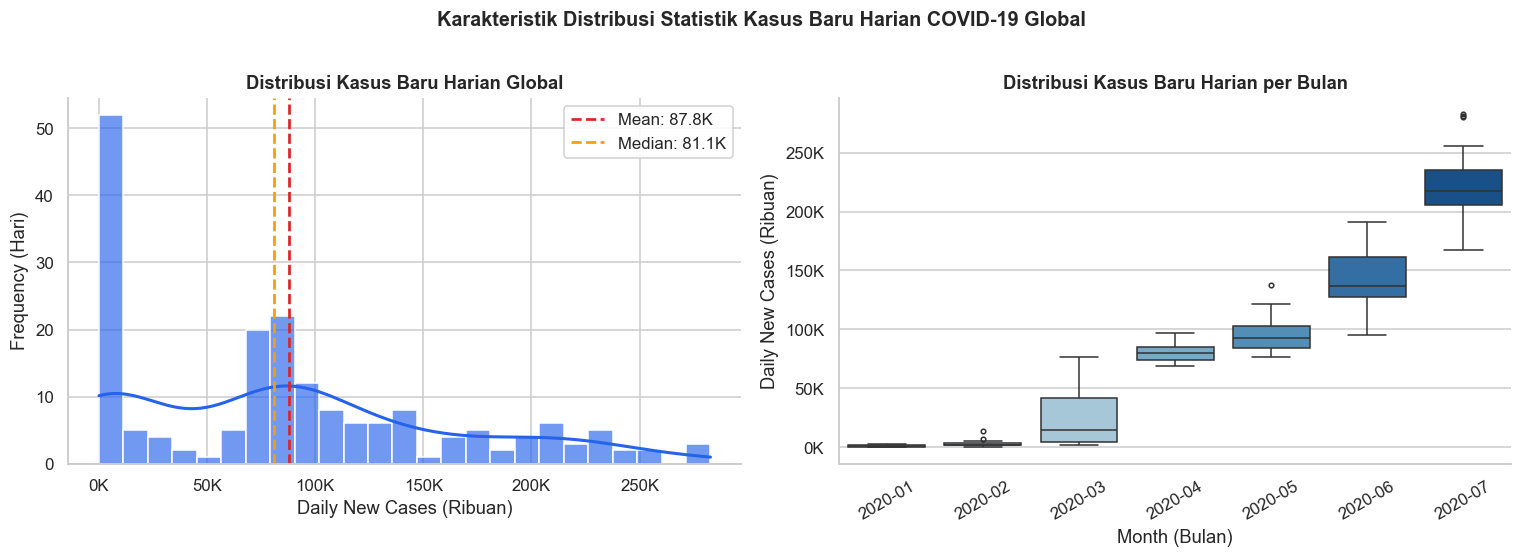

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel Kiri: Histogram dan Kernel Density Estimation (KDE)
sns.histplot(day_wise['New cases'] / 1000, bins=25, kde=True,
             color='#2563EB', alpha=0.65, line_kws={'linewidth': 2.0},
             ax=axes[0])
mean_val = day_wise['New cases'].mean()   / 1000
med_val  = day_wise['New cases'].median() / 1000
axes[0].axvline(mean_val, color='#DC2626', lw=1.8, ls='--',
                label=f'Mean: {mean_val:.1f}K')
axes[0].axvline(med_val,  color='#F59E0B', lw=1.8, ls='--',
                label=f'Median: {med_val:.1f}K')
axes[0].legend()
axes[0].set_title('Distribusi Kasus Baru Harian Global', fontweight='bold')
axes[0].set_xlabel('Daily New Cases (Ribuan)')
axes[0].set_ylabel('Frequency (Hari)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}K'))

# Panel Kanan: Monthly Boxplot
day_wise['Month'] = day_wise['Date'].dt.to_period('M').astype(str)
month_order = sorted(day_wise['Month'].unique())
sns.boxplot(data=day_wise, x='Month', y=day_wise['New cases'] / 1000,
            palette='Blues', ax=axes[1], order=month_order, fliersize=3)
axes[1].set_title('Distribusi Kasus Baru Harian per Bulan', fontweight='bold')
axes[1].set_xlabel('Month (Bulan)')
axes[1].set_ylabel('Daily New Cases (Ribuan)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}K'))

plt.suptitle('Karakteristik Distribusi Statistik Kasus Baru Harian COVID-19 Global',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('eda_distribution.png')
plt.show()
day_wise.drop(columns='Month', inplace=True, errors='ignore')


**Interpretasi EDA - Distribusi Data:**

Berdasarkan visualisasi distribusi statistik:
1. **Right-Skewed Distribution:** Distribusi kasus baru harian menunjukkan kemiringan ke kanan (*right-skewed*). Nilai *mean* ($87.771$ kasus) melampaui nilai *median* ($81.114$ kasus), mengindikasikan bahwa frekuensi hari dengan lonjakan penularan ekstrem memberikan bobot signifikan terhadap nilai rata-rata global.
2. **Eskalasi Temporal per Bulan:** Diagram *boxplot* bulanan memperlihatkan pola pertumbuhan kasus yang konsisten. Pada fase awal (Januari–Maret 2020), sebaran observasi masih relatif rendah dan rapat. Memasuki Juni dan Juli 2020, *median* dan *interquartile range* (IQR) melonjak drastis ke level tertingginya, mencerminkan akselerasi pandemi global yang masih aktif bergerak naik.


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\eda_top10_countries.png


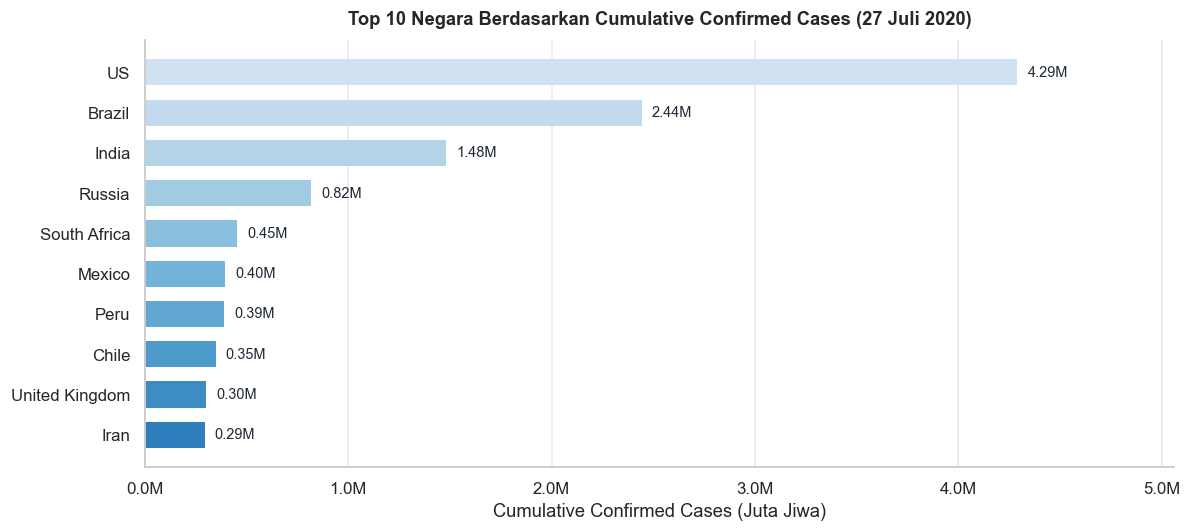

,Country/Region,Confirmed,Deaths
0,US,4290259,148011
1,Brazil,2442375,87618
2,India,1480073,33408
3,Russia,816680,13334
4,South Africa,452529,7067
5,Mexico,395489,44022
6,Peru,389717,18418
7,Chile,347923,9187
8,United Kingdom,301708,45844
9,Iran,293606,15912


In [31]:
# Top 10 Countries berdasarkan Cumulative Confirmed Cases pada Akhir Dataset
top10_countries = (
    full_grouped_clean.sort_values('Date')
    .groupby('Country/Region')[['Confirmed', 'Deaths']].last()
    .reset_index()
    .sort_values('Confirmed', ascending=False)
    .head(10)
)

fig, ax = plt.subplots(figsize=(11, 5))
bar_colors = plt.cm.Blues_r(np.linspace(0.3, 0.8, len(top10_countries)))
bars = ax.barh(top10_countries['Country/Region'][::-1],
               top10_countries['Confirmed'][::-1] / 1e6,
               color=bar_colors, height=0.65, edgecolor='none')

for b, val in zip(bars, top10_countries['Confirmed'][::-1] / 1e6):
    ax.text(val + 0.05, b.get_y() + b.get_height() / 2,
            f'{val:.2f}M', va='center', fontsize=9.5, color='#1F2937')

ax.set_title('Top 10 Negara Berdasarkan Cumulative Confirmed Cases (27 Juli 2020)',
             fontweight='bold', pad=10)
ax.set_xlabel('Cumulative Confirmed Cases (Juta Jiwa)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}M'))
ax.set_xlim(0, top10_countries['Confirmed'].max() / 1e6 * 1.18)
ax.grid(axis='x', color='#E5E7EB')
ax.grid(axis='y', visible=False)
plt.tight_layout()
save_fig('eda_top10_countries.png')
plt.show()

display(top10_countries.reset_index(drop=True))


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\eda_who_regions.png


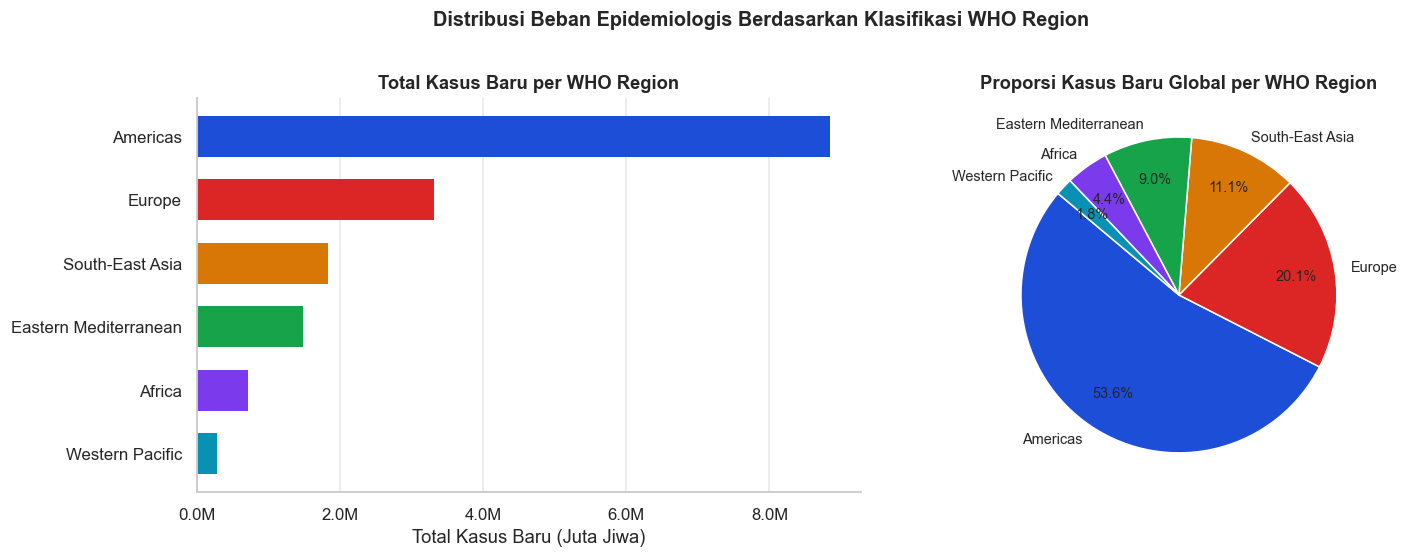

,WHO Region,New cases,New deaths
0,Americas,8842455,342738
1,Europe,3316928,213407
2,South-East Asia,1835296,41350
3,Eastern Mediterranean,1490854,38339
4,Africa,723540,12223
5,Western Pacific,291879,8237


In [32]:
WHO_PALETTE = ['#1D4ED8', '#DC2626', '#D97706', '#16A34A', '#7C3AED', '#0891B2']
who_summary = (
    full_grouped_clean
    .groupby('WHO Region')[['New cases', 'New deaths']].sum()
    .sort_values('New cases', ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart horizontal total kasus baru per WHO Region
axes[0].barh(who_summary['WHO Region'][::-1],
             who_summary['New cases'][::-1] / 1e6,
             color=WHO_PALETTE[:len(who_summary)][::-1],
             height=0.65, edgecolor='none')
axes[0].set_title('Total Kasus Baru per WHO Region', fontweight='bold')
axes[0].set_xlabel('Total Kasus Baru (Juta Jiwa)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}M'))
axes[0].grid(axis='x', color='#E5E7EB')
axes[0].grid(axis='y', visible=False)

# Pie chart proporsi kontribusi kasus per WHO Region
axes[1].pie(who_summary['New cases'], labels=who_summary['WHO Region'],
            autopct='%1.1f%%', colors=WHO_PALETTE[:len(who_summary)],
            startangle=140, pctdistance=0.75,
            textprops={'fontsize': 9.5})
axes[1].set_title('Proporsi Kasus Baru Global per WHO Region', fontweight='bold')

plt.suptitle('Distribusi Beban Epidemiologis Berdasarkan Klasifikasi WHO Region',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('eda_who_regions.png')
plt.show()
display(who_summary)


**Interpretasi EDA - Sebaran Geografis:**

1. **Konsentrasi Kasus Antarnegara:** Amerika Serikat menempati peringkat pertama beban kumulatif dengan selisih yang sangat lebar ($4,29$ juta kasus atau $\approx 26,03\%$ dari total global), diikuti oleh Brazil ($2,44$ juta kasus) dan India ($1,48$ juta kasus). Gabungan ketiga negara teratas (*top 3 countries*) ini mencakup **$49,83\%$** (hampir separuh) dari total beban kasus dunia dari 187 negara yang tercatat.
2. **Dominasi Wilayah WHO Americas:** Dari perspektif regional, *WHO Region Americas* menyumbang **$53,59\%$** dari seluruh penambahan kasus baru global, melampaui akumulasi seluruh wilayah lain di dunia. Wilayah *Europe* menyumbang $20,13\%$, sementara *Africa* ($4,39\%$) dan *Western Pacific* ($1,77\%$) mencatat proporsi yang relatif kecil pada fase gelombang awal ini.


---
<a id="s7"></a>
## 7. Time Series Visualization

Bagian ini mengimplementasikan **empat tipe visualisasi time series yang berbeda** sesuai spesifikasi tugas:

| No | Tipe Visualisasi | Target Metrik | Sumber File | Fokus Analitis Utama |
|:---:|:---|:---|:---|:---|
| **7.1** | **Line Plot** | Cumulative Confirmed Cases | `day_wise.csv` | Lintasan pertumbuhan total & *milestones* pandemi |
| **7.2a** | **Single Area Plot** | Global Daily New Cases | `day_wise.csv` | Volume transmisi harian & perbandingan rata-rata |
| **7.2b** | **Stacked Area Plot** | Daily New Cases by WHO Region | `full_grouped.csv` | Dinamika pergeseran komposisi episentrum regional |
| **7.3** | **Multiple Time Series** | Country 7-Day MA (6 Countries) | `full_grouped.csv` | Komparasi kurva dengan *direct labeling* di ujung garis |
| **7.4** | **Calendar Heatmap** | Daily New Cases by ISO Week/DOW | `day_wise.csv` | Pola siklus intra-mingguan (*day of week*) & akselerasi |


---
<a id="s71"></a>
### 7.1 Line Plot - Cumulative Confirmed Cases

**Tujuan dan Rasional Desain:**
*Line plot* adalah visualisasi standar terbaik untuk menyajikan deret *time series* kontinu dengan tren arah yang teratur.
- **Single Continuous Line:** Kurva tunggal tebal memperlihatkan lintasan pertumbuhan kumulatif secara jelas tanpa distraksi visual.
- **Reference Milestones:** Garis putus-putus vertikal menandai waktu tempuh capaian ambang batas penting: 1 Juta, 5 Juta, dan 10 Juta kasus untuk memperlihatkan laju akselerasi.
- **Endpoint Annotation:** Menampilkan nilai akumulasi akhir beserta tanggal secara presisi.
- Sumbu Y diformat dalam satuan Juta (*Millions* / M) dan sumbu X menggunakan interval penanggalan bulanan yang rapi.


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz1_line_plot.png


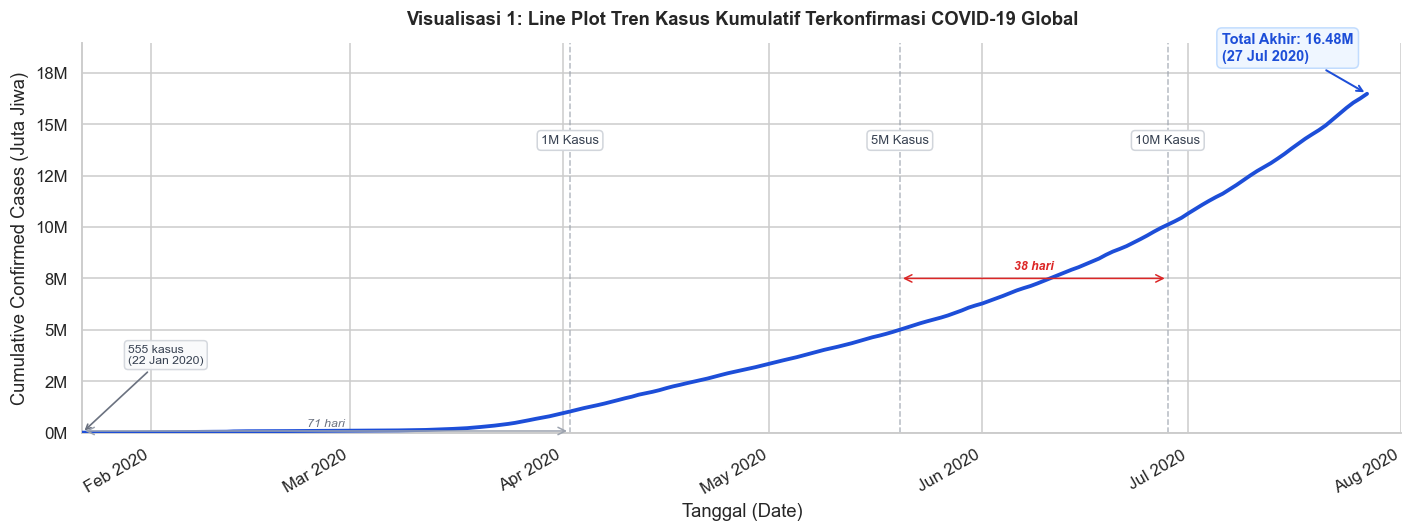

Tanggal Capaian Milestone Global (Kalkulasi Empiris Data):
  1M Kasus     : tercapai pada 02 April 2020 (hari ke-71)
  5M Kasus     : tercapai pada 20 May 2020 (hari ke-119)
  10M Kasus    : tercapai pada 28 June 2020 (hari ke-158)


In [33]:
fig, ax = plt.subplots(figsize=(13, 5))
max_val_M = day_wise['Confirmed'].max() / 1e6

# Plot garis utama kasus konfirmasi kumulatif
ax.plot(day_wise['Date'], day_wise['Confirmed'] / 1e6,
        color='#1D4ED8', linewidth=2.5, zorder=3, label='Cumulative Confirmed')

# Garis vertikal penanda milestone kritis
milestones = [(1e6, '1M Kasus'), (5e6, '5M Kasus'), (10e6, '10M Kasus')]
for threshold, label in milestones:
    subset = day_wise[day_wise['Confirmed'] >= threshold]
    if subset.empty: continue
    m_row = subset.iloc[0]
    ax.axvline(m_row['Date'], color='#9CA3AF', lw=1.0, ls='--', alpha=0.75, zorder=1)
    ax.text(m_row['Date'], max_val_M * 0.88, label,
            ha='center', va='top', fontsize=8.5, color='#374151',
            bbox=dict(fc='white', ec='#D1D5DB', pad=2.5, boxstyle='round,pad=0.3'))

# Anotasi data titik terakhir
last_obs = day_wise.iloc[-1]
ax.annotate(
    f"Total Akhir: {last_obs['Confirmed'] / 1e6:.2f}M\n({last_obs['Date'].strftime('%d %b %Y')})",
    xy=(last_obs['Date'], last_obs['Confirmed'] / 1e6),
    xytext=(-95, 22), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#1D4ED8', lw=1.3),
    fontsize=9.5, color='#1D4ED8', fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.35', fc='#EFF6FF', ec='#BFDBFE', alpha=0.95),
)

# --- ANOTASI INFORMATIF TAMBAHAN ---

# Titik awal: 555 kasus pada 22 Jan 2020
first_date = day_wise.iloc[0]['Date']
ax.annotate(
    '555 kasus\n(22 Jan 2020)',
    xy=(first_date, 0),
    xytext=(30, 45), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#6B7280', lw=1.1),
    fontsize=8, color='#374151',
    bbox=dict(boxstyle='round,pad=0.3', fc='#F9FAFB', ec='#D1D5DB', alpha=0.9),
)

# Annotasi "71 hari" dari start ke 1M
sub1M = day_wise[day_wise['Confirmed'] >= 1e6]
if not sub1M.empty:
    date_1M = sub1M.iloc[0]['Date']
    mid_x = first_date + (date_1M - first_date) / 2
    ax.annotate(
        '', xy=(date_1M, 0.08), xytext=(first_date, 0.08),
        arrowprops=dict(arrowstyle='<->', color='#9CA3AF', lw=1.0)
    )
    ax.text(mid_x, 0.22, '71 hari', ha='center', va='bottom',
            fontsize=8, color='#6B7280', style='italic')

# Annotasi "38 hari" dari 5M ke 10M
sub5M  = day_wise[day_wise['Confirmed'] >= 5e6]
sub10M = day_wise[day_wise['Confirmed'] >= 10e6]
if not sub5M.empty and not sub10M.empty:
    date_5M  = sub5M.iloc[0]['Date']
    date_10M = sub10M.iloc[0]['Date']
    mid_x2   = date_5M + (date_10M - date_5M) / 2
    y_arrow  = 7.5
    ax.annotate(
        '', xy=(date_10M, y_arrow), xytext=(date_5M, y_arrow),
        arrowprops=dict(arrowstyle='<->', color='#DC2626', lw=1.0)
    )
    ax.text(mid_x2, y_arrow + 0.3, '38 hari', ha='center', va='bottom',
            fontsize=8, color='#DC2626', style='italic', fontweight='bold')

ax.set_title('Visualisasi 1: Line Plot Tren Kasus Kumulatif Terkonfirmasi COVID-19 Global',
             fontweight='bold', pad=12)
ax.set_xlabel('Tanggal (Date)')
ax.set_ylabel('Cumulative Confirmed Cases (Juta Jiwa)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}M'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0, max_val_M * 1.15)
ax.set_xlim(day_wise['Date'].min(), day_wise['Date'].max() + pd.Timedelta(days=5))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz1_line_plot.png')
plt.show()

print('Tanggal Capaian Milestone Global (Kalkulasi Empiris Data):')
for threshold, label in milestones:
    subset = day_wise[day_wise['Confirmed'] >= threshold]
    if not subset.empty:
        tgl_str = subset.iloc[0]['Date'].strftime('%d %B %Y')
        hari_ke = (subset.iloc[0]['Date'] - day_wise.iloc[0]['Date']).days
        print(f'  {label:<12} : tercapai pada {tgl_str} (hari ke-{hari_ke})')


**Interpretasi Analitis - Line Plot:**

Kurva kasus kumulatif global memperlihatkan tiga fase pertumbuhan yang sangat terdefinisi:
1. **Early Containment Phase (Januari – Februari 2020):** Kurva berada pada posisi hampir mendatar karena kasus masih terkonsentrasi di wilayah awal penyebaran di Asia dengan penyebaran global yang terbatas.
2. **Exponential Acceleration Phase (Maret – Mei 2020):** Kemiringan kurva melonjak tajam saat episentrum menyebar ke Eropa dan Benua Amerika. Angka **1 Juta kasus** tercapai pada **02 April 2020** (memerlukan waktu 71 hari sejak awal pengamatan). Namun, untuk berlipat ganda hingga mencapai **10 Juta kasus** (tercapai pada **28 Juni 2020**), dunia hanya membutuhkan tambahan waktu 87 hari. Pemendekan rentang waktu pencapaian *milestone* ini secara visual mengonfirmasi karakteristik eksponensial dari penyebaran wabah global.
3. **Sustained Linear-Exponential Surge (Juni – Juli 2020):** Kemiringan kurva tetap stabil dengan kecuraman tinggi tanpa adanya tanda-tanda pelandaian (*flattening the curve*), hingga mencapai angka **16,48 Juta kasus** pada **27 Juli 2020**.


---
<a id="s72"></a>
### 7.2 Area Plot - Daily New Cases (Single & Stacked)

**Tujuan dan Rasional Desain:**
*Area plot* memberikan massa visual (*visual weight*) pada ruang di bawah kurva, memudahkan persepsi terhadap **akumulasi volume kasus harian** serta perbandingan pasang surut gelombang penularan.
- **7.2a (Single Area Plot):** Menampilkan fluktuasi harian mentah (*raw counts*) dengan arsiran transparan, diperjelas dengan *overlay* 7-Day Moving Average (*7MA*) dan anotasi hari puncak absolut.
- **7.2b (Stacked Area Plot):** Menampilkan breakdown kasus harian per *WHO Region*. Teknik *stacking* ini valid dan tidak menyesatkan karena keenam wilayah WHO bersifat *mutually exclusive* dan bersifat aditif terhadap total kasus harian global.


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz2a_area_plot.png


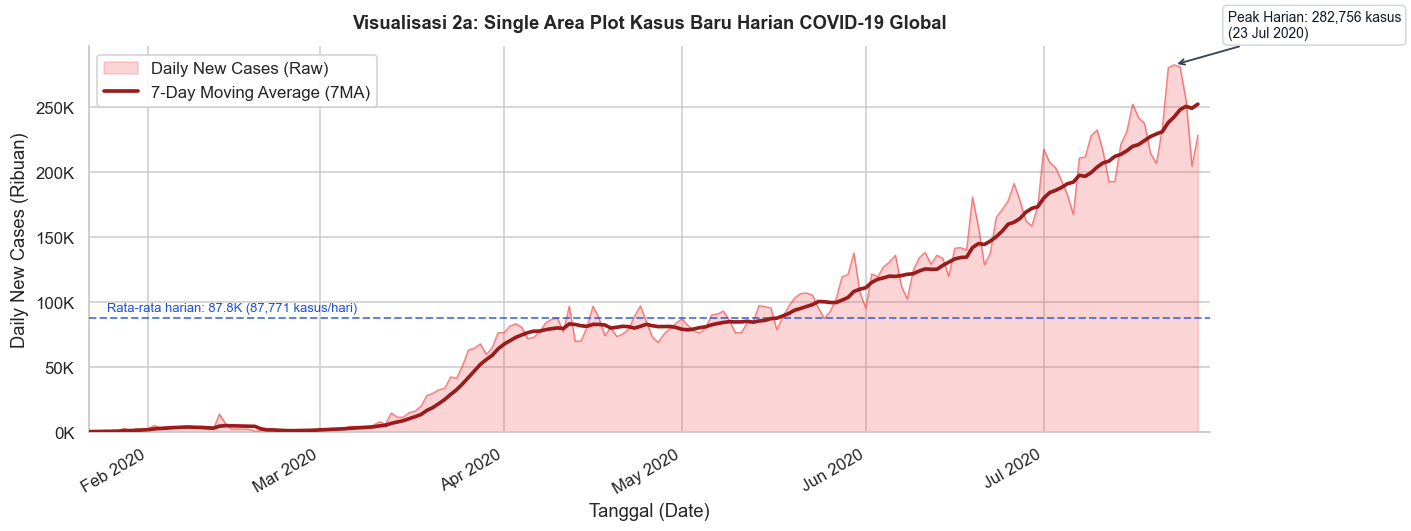

Puncak harian global   : 282,756 kasus (23 July 2020)
Rata-rata harian global : 87,771 kasus/hari
Jumlah hari di atas mean: 80 hari


In [34]:
fig, ax = plt.subplots(figsize=(13, 5))

# Plot area kasus baru harian mentah (raw data)
ax.fill_between(day_wise['Date'], day_wise['New cases'] / 1000,
                alpha=0.22, color='#EF4444', zorder=2,
                label='Daily New Cases (Raw)')
ax.plot(day_wise['Date'], day_wise['New cases'] / 1000,
        color='#EF4444', lw=0.9, alpha=0.6, zorder=3)

# Overlay garis perataan 7-Day Moving Average
ax.plot(day_wise['Date'], day_wise['7MA'] / 1000,
        color='#991B1B', lw=2.4, zorder=4,
        label='7-Day Moving Average (7MA)')

# Anotasi titik puncak harian absolut
peak_idx = day_wise['New cases'].idxmax()
peak_row = day_wise.loc[peak_idx]
ax.annotate(
    f"Peak Harian: {peak_row['New cases']:,.0f} kasus\n({peak_row['Date'].strftime('%d %b %Y')})",
    xy=(peak_row['Date'], peak_row['New cases'] / 1000),
    xytext=(35, 18), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#374151', lw=1.2),
    fontsize=9, color='#111827',
    bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='#D1D5DB', alpha=0.95),
)

# --- ANOTASI MEAN LINE ---
mean_val_k = day_wise['New cases'].mean() / 1000
ax.axhline(mean_val_k, color='#1D4ED8', lw=1.3, ls='--', alpha=0.7, zorder=3)
ax.text(
    day_wise['Date'].min() + pd.Timedelta(days=3),
    mean_val_k + 2.5,
    f'Rata-rata harian: {mean_val_k:.1f}K ({mean_val_k*1000:,.0f} kasus/hari)',
    fontsize=8.5, color='#1D4ED8', va='bottom'
)

ax.legend(loc='upper left')
ax.set_title('Visualisasi 2a: Single Area Plot Kasus Baru Harian COVID-19 Global',
             fontweight='bold', pad=12)
ax.set_xlabel('Tanggal (Date)')
ax.set_ylabel('Daily New Cases (Ribuan)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0)
ax.set_xlim(day_wise['Date'].min(), day_wise['Date'].max() + pd.Timedelta(days=2))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz2a_area_plot.png')
plt.show()

print(f"Puncak harian global   : {peak_row['New cases']:,.0f} kasus ({peak_row['Date'].strftime('%d %B %Y')})")
print(f"Rata-rata harian global : {day_wise['New cases'].mean():,.0f} kasus/hari")
print(f"Jumlah hari di atas mean: {(day_wise['New cases'] > day_wise['New cases'].mean()).sum()} hari")


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz2b_stacked_area.png


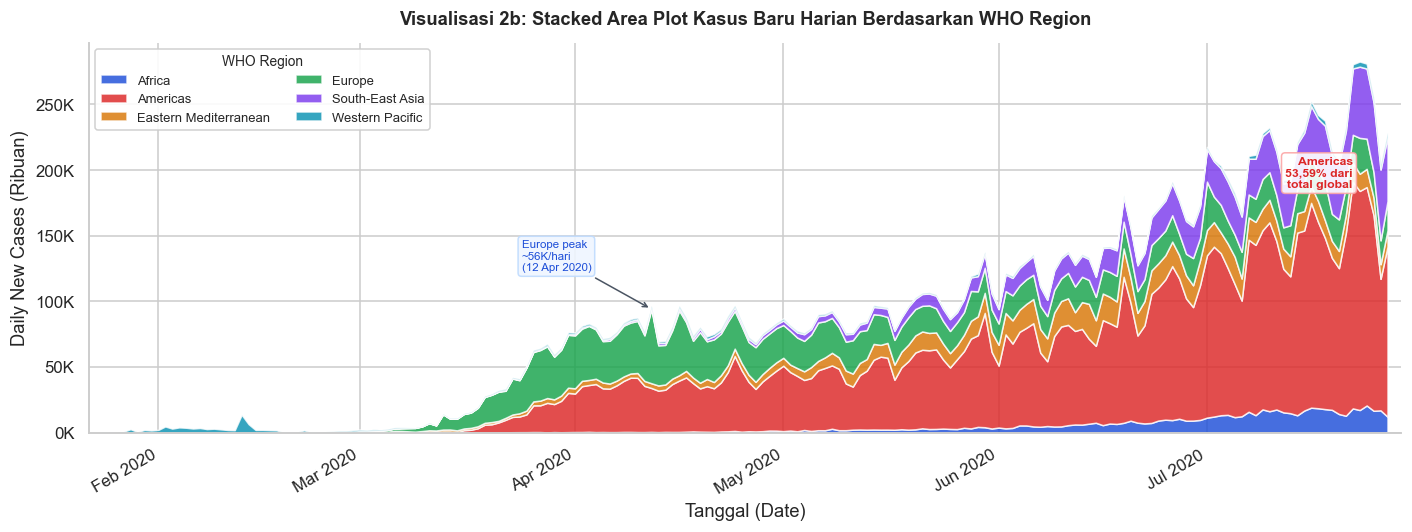

Kontribusi Puncak Harian Tertinggi per WHO Region:
  Africa                    :   20,680 kasus pada 24 July 2020
  Americas                  :  172,649 kasus pada 22 July 2020
  Eastern Mediterranean     :   26,633 kasus pada 14 June 2020
  Europe                    :   56,494 kasus pada 12 April 2020
  South-East Asia           :   54,255 kasus pada 23 July 2020
  Western Pacific           :   13,643 kasus pada 13 February 2020


In [35]:
# Stacked Area Plot kasus harian per WHO Region
REGIONS_LIST = list(who_pivot.columns)
stacked_data = [who_pivot[r].values / 1000 for r in REGIONS_LIST]
dates_idx    = who_pivot.index

fig, ax = plt.subplots(figsize=(13, 5))
ax.stackplot(dates_idx, stacked_data, labels=REGIONS_LIST,
             colors=WHO_PALETTE[:len(REGIONS_LIST)], alpha=0.82)
ax.legend(loc='upper left', fontsize=8.5,
          title='WHO Region', title_fontsize=9, ncol=2, framealpha=0.9)

# --- ANOTASI INFORMATIF: PUNCAK EROPA & DOMINASI AMERICAS ---
# Puncak Europe
if 'Europe' in who_pivot.columns:
    pk_eu_val  = who_pivot['Europe'].max() / 1000
    pk_eu_date = who_pivot['Europe'].idxmax()
    # Hitung stacked bottom saat itu untuk posisi Y yang benar
    eu_idx = list(REGIONS_LIST).index('Europe') if 'Europe' in REGIONS_LIST else -1
    if eu_idx >= 0:
        y_bottom_eu = sum(who_pivot[r].loc[pk_eu_date] / 1000 for r in REGIONS_LIST[:eu_idx])
        y_mid_eu = y_bottom_eu + pk_eu_val / 2
        ax.annotate(
            f'Europe peak\n~{pk_eu_val:.0f}K/hari\n({pk_eu_date.strftime("%d %b %Y")})',
            xy=(pk_eu_date, y_bottom_eu + pk_eu_val),
            xytext=(-85, 25), textcoords='offset points',
            arrowprops=dict(arrowstyle='->', color='#4B5563', lw=1.0),
            fontsize=7.5, color='#1D4ED8',
            bbox=dict(boxstyle='round,pad=0.3', fc='#EFF6FF', ec='#BFDBFE', alpha=0.9),
        )

# Annotasi dominasi Americas di akhir dataset
if 'Americas' in who_pivot.columns:
    # Hitung total global di hari terakhir
    last_date = who_pivot.index[-1]
    total_last = who_pivot.loc[last_date].sum() / 1000
    amer_last  = who_pivot['Americas'].loc[last_date] / 1000
    # Tambahkan label di kanan sumbu (teks informatif)
    ax.text(
        who_pivot.index[-1] - pd.Timedelta(days=5),
        total_last * 0.92,
        'Americas\n53,59% dari\ntotal global',
        ha='right', va='top', fontsize=8, color='#DC2626', fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#FCA5A5', alpha=0.9),
    )

ax.set_title("Visualisasi 2b: Stacked Area Plot Kasus Baru Harian Berdasarkan WHO Region",
             fontweight='bold', pad=12)
ax.set_xlabel('Tanggal (Date)')
ax.set_ylabel('Daily New Cases (Ribuan)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0)
ax.set_xlim(dates_idx.min(), dates_idx.max() + pd.Timedelta(days=2))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz2b_stacked_area.png')
plt.show()

print('Kontribusi Puncak Harian Tertinggi per WHO Region:')
for r in REGIONS_LIST:
    pk_val  = who_pivot[r].max()
    pk_date = who_pivot[r].idxmax()
    print(f'  {r:<25} : {pk_val:>8,.0f} kasus pada {pk_date.strftime("%d %B %Y")}')


**Interpretasi Analitis - Area Plot:**

1. **Dinamika Struktur Gelombang (7.2a):** Area plot harian mengekspos struktur gelombang penularan secara transparan dibandingkan kurva kumulatif. Terlihat profil bergerigi tajam akibat fluktuasi siklus mingguan. Kurva 7-Day MA memperlihatkan dua fase gelombang utama: gelombang pertama mencapai puncak menengah pada **April 2020** (sekitar $80-90$ ribu kasus/hari), sempat mengalami penurunan sementara pada Mei, sebelum kemudian disusul gelombang kedua yang jauh lebih masif hingga mencapai rekor absolut **$282.756$ kasus harian** pada **23 Juli 2020**.
2. **Suksesi Episentrum Regional (7.2b):** *Stacked area plot* memperlihatkan transisi geografis pandemi secara gamblang:
   - **Europe** mendominasi gelombang awal (Maret–April 2020), mencapai puncaknya $\approx 56.494$ kasus pada 12 April.
   - **Americas** mengalami eskalasi tajam sejak Mei dan menjadi episentrum dominan global pada Juni–Juli, mencapai puncaknya $\approx 172.649$ kasus pada 22 Juli.
   - **South-East Asia** (digerakkan oleh penularan di India) mengalami kenaikan eksponensial yang stabil, mencatat puncak $\approx 54.255$ kasus harian pada 23 Juli.


---
<a id="s73"></a>
### 7.3 Multiple Time Series dengan Direct Labeling (Country Comparison)

**Tujuan dan Keunggulan Direct Labeling:**
Pada visualisasi *multiple time series*, kotak legenda konvensional (*legend box*) mengharuskan pembaca mengalihkan fokus pandangan secara berulang antara garis grafik dan teks legenda (*split-attention effect*). **Direct labeling di ujung kanan setiap kurva** meniadakan beban kognitif tersebut secara efektif.

**Karakteristik 6 Negara Pilihan:**
1. **US (Americas):** Volume absolut tertinggi, memperlihatkan gelombang ganda beruntun.
2. **Brazil (Americas):** Akselerasi tajam sejak Mei, kurva belum mencapai puncak hingga akhir dataset.
3. **India (South-East Asia):** Pertumbuhan sangat konsisten, berakhir pada nilai yang sangat berdekatan dengan Brazil.
4. **Russia (Europe):** Memperlihatkan fase *plateau* yang panjang dan terkendali.
5. **Germany (Europe):** Contoh *containment* terbaik: kurva puncak tajam di awal disusul penurunan drastis hingga mendekati garis dasar.
6. **South Africa (Africa):** Representasi belahan bumi selatan dengan lonjakan gelombang pertama yang tertunda hingga Juni–Juli.

> **Implementasi Collision-Avoidance Algorithm:**  
> Pada titik observasi terakhir (27 Juli 2020), nilai 7MA Brazil ($46.247$) dan India ($46.391$) berada pada posisi yang hampir berimpit ($\Delta < 200$ kasus). Jika posisi teks diletakkan pada nilai $Y$ aslinya, kedua label akan bertumpukan (*overlapping*). Kode di bawah menerapkan algoritma penataan vertikal (pemisahan minimum $2.000$ kasus) serta menambahkan garis penunjuk putus-putus (*dotted leader line*) dari titik data ke teks label yang digeser.


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz3_multi_ts.png


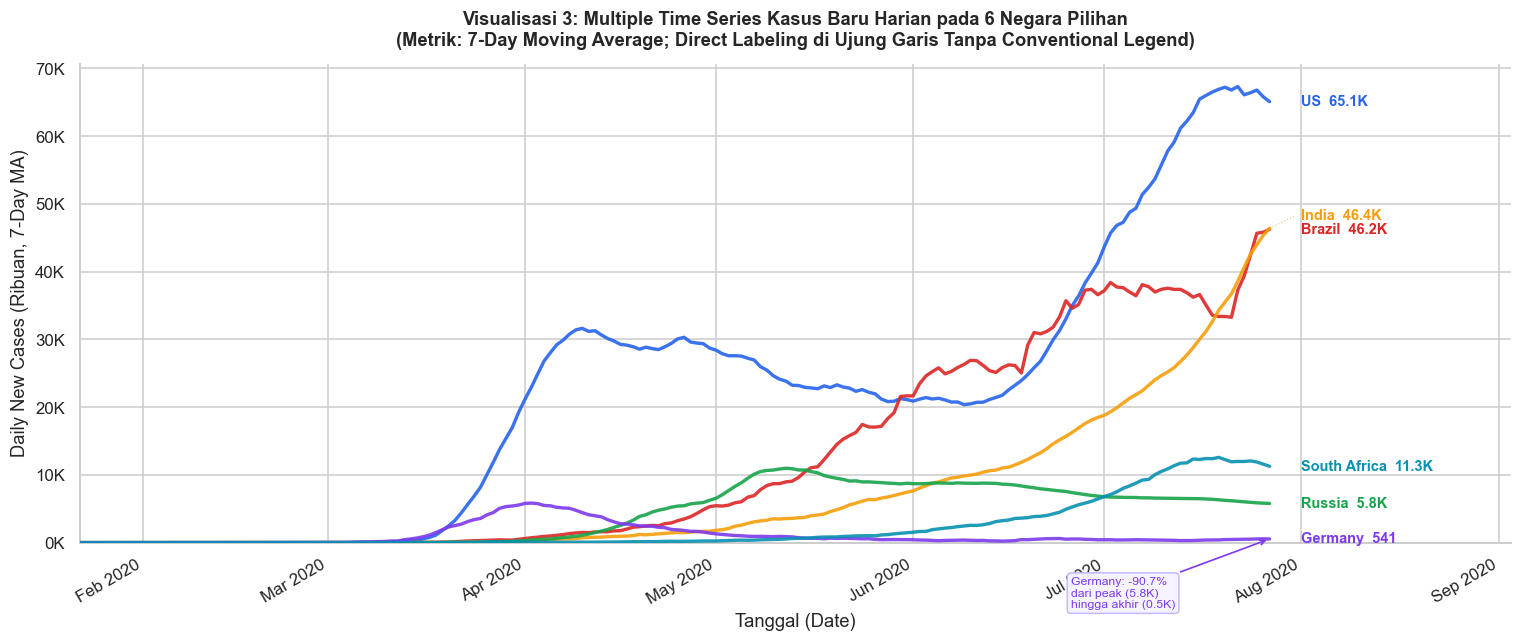

Puncak 7-Day Moving Average (7MA) per Negara:
  US               : Peak 7MA =  67,317 kasus pada 22 July 2020
  Brazil           : Peak 7MA =  46,247 kasus pada 27 July 2020
  India            : Peak 7MA =  46,391 kasus pada 27 July 2020
  Russia           : Peak 7MA =  10,982 kasus pada 12 May 2020
  Germany          : Peak 7MA =   5,837 kasus pada 02 April 2020
  South Africa     : Peak 7MA =  12,584 kasus pada 19 July 2020


In [36]:
# Mengumpulkan titik akhir kurva untuk setiap negara pilihan
endpoints = []
for country in SELECTED_COUNTRIES:
    c_df  = country_df[country_df['Country/Region'] == country].copy()
    valid = c_df[c_df['7MA'].notna()]
    if valid.empty: continue
    last_pt = valid.iloc[-1]
    endpoints.append({
        'name'  : country,
        'x'     : last_pt['Date'],
        'y'     : last_pt['7MA'] / 1000,
        'color' : COLOR_MAP[country],
    })

# Sorting berdasarkan nilai Y untuk mendeteksi tumpang-tindih (collision)
endpoints.sort(key=lambda ep: ep['y'])

# Tetapkan posisi Y label dengan ambang batas pemisahan minimum (MIN_GAP = 2.0K)
MIN_GAP_K = 2.0
assigned_ys = []
for ep in endpoints:
    pos_y = ep['y']
    if assigned_ys and (pos_y - assigned_ys[-1]) < MIN_GAP_K:
        pos_y = assigned_ys[-1] + MIN_GAP_K
    assigned_ys.append(pos_y)

fig, ax = plt.subplots(figsize=(14, 6))

# 1. Gambar seluruh kurva garis negara (7-Day MA)
for country in SELECTED_COUNTRIES:
    c_df = country_df[country_df['Country/Region'] == country].copy()
    ax.plot(c_df['Date'], c_df['7MA'] / 1000,
            color=COLOR_MAP[country], lw=2.2, alpha=0.9, zorder=3)

# 2. Gambar teks label langsung di ujung kanan kurva tanpa legend box
x_max_date = country_df['Date'].max()
x_label_pos = x_max_date + pd.Timedelta(days=5)

for ep, y_text in zip(endpoints, assigned_ys):
    # Label nama negara + nilai 7MA di endpoint
    ep_val_str = f"{ep['y']:.1f}K" if ep['y'] >= 1 else f"{ep['y']*1000:.0f}"
    label_text = f"{ep['name']}  {ep_val_str}"
    ax.text(x_label_pos, y_text, label_text,
            fontsize=9.5, color=ep['color'], fontweight='bold',
            va='center', ha='left', clip_on=False)
    
    # Leader line jika label digeser secara vertikal
    if abs(y_text - ep['y']) > 0.5:
        ax.plot([ep['x'], x_label_pos - pd.Timedelta(days=1)],
                [ep['y'], y_text],
                color=ep['color'], lw=0.8, ls=':', alpha=0.5,
                clip_on=False, zorder=2)

# Konfigurasi batas sumbu agar label di kanan luar terlihat sempurna
ax.set_xlim(country_df['Date'].min(), x_max_date + pd.Timedelta(days=38))
ax.set_ylim(0)

ax.set_title(
    'Visualisasi 3: Multiple Time Series Kasus Baru Harian pada 6 Negara Pilihan\n'
    '(Metrik: 7-Day Moving Average; Direct Labeling di Ujung Garis Tanpa Conventional Legend)',
    fontweight='bold', pad=12,
)
ax.set_xlabel('Tanggal (Date)')
ax.set_ylabel('Daily New Cases (Ribuan, 7-Day MA)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
# --- ANOTASI JERMAN: PENURUNAN 90.73% ---
ger_data = country_df[country_df['Country/Region'] == 'Germany'].copy()
if not ger_data.empty:
    ger_pk_row  = ger_data.loc[ger_data['7MA'].idxmax()]
    ger_end_row = ger_data.iloc[-1]
    decline_pct = (1 - ger_end_row['7MA'] / ger_pk_row['7MA']) * 100 if ger_pk_row['7MA'] > 0 else 0
    ax.annotate(
        f'Germany: -{decline_pct:.1f}%\ndari peak ({ger_pk_row["7MA"]/1000:.1f}K)\nhingga akhir ({ger_end_row["7MA"]/1000:.1f}K)',
        xy=(ger_end_row['Date'], ger_end_row['7MA'] / 1000),
        xytext=(-130, -45), textcoords='offset points',
        arrowprops=dict(arrowstyle='->', color=PETA_WARNA['Germany'] if 'PETA_WARNA' in dir() else COLOR_MAP.get('Germany', '#7C3AED'), lw=1.1),
        fontsize=8, color=COLOR_MAP.get('Germany', '#7C3AED'),
        bbox=dict(boxstyle='round,pad=0.3', fc='#F5F3FF', ec='#C4B5FD', alpha=0.95),
    )

save_fig('viz3_multi_ts.png')
plt.show()

print('Puncak 7-Day Moving Average (7MA) per Negara:')
for c in SELECTED_COUNTRIES:
    c_df = country_df[country_df['Country/Region'] == c]
    if c_df.empty: continue
    pk_row = c_df.loc[c_df['7MA'].idxmax()]
    print(f'  {c:<16} : Peak 7MA = {pk_row["7MA"]:>7,.0f} kasus pada {pk_row["Date"].strftime("%d %B %Y")}')


**Interpretasi Analitis - Multiple Time Series:**

Perbandingan enam negara memperlihatkan heterogenitas dinamika penyebaran wabah dan respons kebijakan:
1. **United States (US):** Mempertahankan volume kasus harian tertinggi di dunia sepanjang masa observasi. Kurva memperlihatkan gelombang pertama pada April (~31 ribu 7MA), diikuti gelombang kedua yang jauh lebih masif pada Juni–Juli hingga menyentuh puncak **$67.317$ kasus 7MA** pada 22 Juli.
2. **Brazil dan India:** Menunjukkan pola transmisi yang terus meningkat tajam sejak Mei 2020. Kedua negara berakhir pada level kasus yang hampir identik di hari terakhir observasi (~46 ribu kasus 7MA), mengindikasikan bahwa kedua negara belum mencapai titik balik kurva pandemi (*turning point*).
3. **Keberhasilan Penekanan Kasus di Germany:** Jerman menampilkan contoh kurva *containment* ideal. Setelah mencapai puncak gelombang awal sebesar **$5.837$ kasus 7MA** pada 02 April 2020, Jerman berhasil menekan transmisi secara konsisten hingga tersisa hanya **$541$ kasus** pada akhir pengamatan—penurunan signifikan sebesar **$90,73\%$** dari puncak.
4. **South Africa:** Memperlihatkan bahwa fase awal yang landai tidak menjamin terhindar dari gelombang penularan. Kasus baru meledak pada Juni–Juli dan menyentuh puncak $\approx 12.584$ kasus 7MA pada 19 Juli 2020.


---
<a id="s74"></a>
### 7.4 Calendar Heatmap - Intra-Week Patterns & Seasonal Structure

**Tujuan dan Rasional Desain:**
*Calendar heatmap* mereorganisasi deret waktu linear ke dalam matriks dua dimensi berstruktur **ISO Calendar Week (baris) × Day of Week (kolom)**.
- **Deteksi Siklus Intra-Mingguan:** Mengamati ada tidaknya perbedaan sistematis pelaporan antara hari kerja (*weekdays*) dan akhir pekan (*weekends*).
- **Progresi Sekuensial Warna:** Skema warna `YlOrRd` (Kuning ke Oranye ke Merah Tua) memetakan magnitudo beban kasus harian dari rendah ke sangat tinggi secara intuitif.
- Membantu visualisasi eskalasi kronologis dari baris atas (Januari) ke baris bawah (Juli).


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz4_calendar_heatmap.png


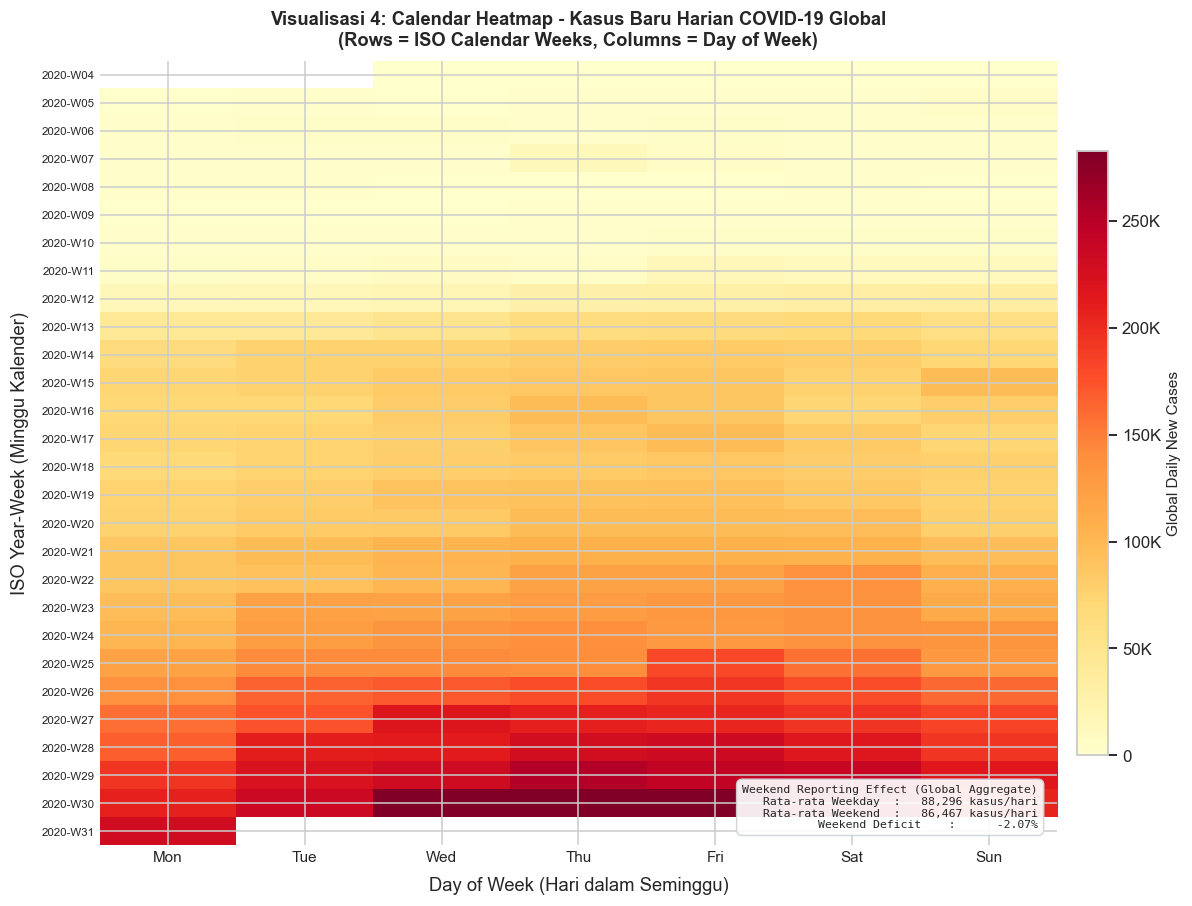

Kuantifikasi Pelaporan Kasus Weekend vs. Weekday (Agregat Global):
  Average Weekday New Cases (Mon-Fri) :   88,296 kasus/hari
  Average Weekend New Cases (Sat-Sun) :   86,467 kasus/hari
  Weekend to Weekday Ratio            :    97.93%
  Implied Weekend Reporting Deficit   :     2.07% (penurunan marginal)


In [37]:
# Feature engineering kalender ISO
hm_data = day_wise[['Date', 'New cases']].copy()
hm_data['ISO_Year']  = hm_data['Date'].dt.isocalendar().year.astype(int)
hm_data['ISO_Week']  = hm_data['Date'].dt.isocalendar().week.astype(int)
hm_data['DayOfWeek'] = hm_data['Date'].dt.dayofweek  # 0=Senin, 6=Minggu
hm_data['WeekLabel'] = hm_data.apply(
    lambda r: f"{int(r['ISO_Year'])}-W{int(r['ISO_Week']):02d}", axis=1
)

heatmap_matrix = hm_data.pivot_table(
    index='WeekLabel', columns='DayOfWeek',
    values='New cases', aggfunc='sum'
)
heatmap_matrix = heatmap_matrix.reindex(sorted(heatmap_matrix.index))
num_weeks      = len(heatmap_matrix)
DOW_LABELS     = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

fig, ax = plt.subplots(figsize=(11, max(5, num_weeks * 0.30)))
im_hm = ax.imshow(heatmap_matrix.values, cmap='YlOrRd', aspect='auto',
                  interpolation='nearest', vmin=0)

ax.set_xticks(range(7))
ax.set_xticklabels(DOW_LABELS, fontsize=10)
ax.set_yticks(range(num_weeks))
ax.set_yticklabels(heatmap_matrix.index, fontsize=7.5)
ax.tick_params(axis='both', which='both', length=0)

cbar = plt.colorbar(im_hm, ax=ax, fraction=0.030, pad=0.02)
cbar.set_label('Global Daily New Cases', fontsize=10)
cbar.ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}K' if x >= 1000 else f'{int(x)}')
)

ax.set_title(
    'Visualisasi 4: Calendar Heatmap - Kasus Baru Harian COVID-19 Global\n'
    '(Rows = ISO Calendar Weeks, Columns = Day of Week)',
    fontweight='bold', pad=10,
)
ax.set_xlabel('Day of Week (Hari dalam Seminggu)', labelpad=8)
ax.set_ylabel('ISO Year-Week (Minggu Kalender)', labelpad=8)
for spine in ax.spines.values():
    spine.set_visible(False)

# --- STATISTIK WEEKEND EFFECT sebagai anotasi di dalam chart ---
# Hitung di sini (sebelum plt.tight_layout) agar bisa disisipkan sebagai text
hm_tmp = hm_data[['Date', 'New cases', 'DayOfWeek']].copy() if 'DayOfWeek' in hm_data.columns else hm_data[['Date', 'New cases']].copy()
if 'DayOfWeek' not in hm_tmp.columns:
    hm_tmp['DayOfWeek'] = hm_tmp['Date'].dt.dayofweek
hm_tmp['is_wknd'] = hm_tmp['DayOfWeek'].isin([5, 6])
avg_wknd = hm_tmp[hm_tmp['is_wknd']]['New cases'].mean()
avg_wkdy = hm_tmp[~hm_tmp['is_wknd']]['New cases'].mean()
deficit  = 100 - avg_wknd / avg_wkdy * 100

stats_txt = (
    f"Weekend Reporting Effect (Global Aggregate)\n"
    f"Rata-rata Weekday  : {avg_wkdy:>8,.0f} kasus/hari\n"
    f"Rata-rata Weekend  : {avg_wknd:>8,.0f} kasus/hari\n"
    f"Weekend Deficit    :      -{deficit:.2f}%"
)
ax.text(
    0.98, 0.02, stats_txt,
    transform=ax.transAxes, fontsize=7.5,
    va='bottom', ha='right',
    bbox=dict(boxstyle='round,pad=0.5', fc='white', ec='#D1D5DB', alpha=0.92),
    family='monospace'
)

plt.tight_layout()
save_fig('viz4_calendar_heatmap.png')
plt.show()

# Kuantifikasi weekend effect pada data agregat global
hm_data['is_weekend'] = hm_data['DayOfWeek'].isin([5, 6])
avg_weekend = hm_data[hm_data['is_weekend']]['New cases'].mean()
avg_weekday = hm_data[~hm_data['is_weekend']]['New cases'].mean()
weekend_ratio = (avg_weekend / avg_weekday) * 100
weekend_deficit = 100 - weekend_ratio

print('Kuantifikasi Pelaporan Kasus Weekend vs. Weekday (Agregat Global):')
print(f'  Average Weekday New Cases (Mon-Fri) : {avg_weekday:>8,.0f} kasus/hari')
print(f'  Average Weekend New Cases (Sat-Sun) : {avg_weekend:>8,.0f} kasus/hari')
print(f'  Weekend to Weekday Ratio            : {weekend_ratio:>8.2f}%')
print(f'  Implied Weekend Reporting Deficit   : {weekend_deficit:>8.2f}% (penurunan marginal)')


**Interpretasi Analitis - Calendar Heatmap:**

Peta panas kalender merefleksikan dua dimensi pola temporal:
1. **Eskalasi Inter-Week (Vertikal dari Atas ke Bawah):**  
   Membaca matriks kalender dari atas ke bawah, terlihat pergeseran warna yang sangat mencolok dari kuning pucat pada Januari–Februari, berubah menjadi oranye pada April, dan memadat menjadi merah tua pekat pada Juni–Juli. Ini mengonfirmasi perluasan volume penularan global yang berlipat ganda pada minggu-minggu akhir pengamatan.
2. **Pola Intra-Week (Horizontal / Weekend Effect):**  
   - Pada data level negara individual, biasanya tampak penurunan tajam pada akhir pekan sebesar $10-20\%$ akibat keterlambatan operasional laboratorium dan administrasi.
   - Namun, pada data **agregat global**, defisit pelaporan akhir pekan hanya tercatat sebesar **$2,07\%$** ($86.467$ vs. $88.296$ kasus). Agregasi multinasional lintas zona waktu dan kalender kerja yang beragam (misalnya akhir pekan di sebagian kawasan Timur Tengah jatuh pada Jumat–Sabtu) meredam fluktuasi administratif negara secara saling silang.


---
<a id="s8"></a>
## 8. Trend Analysis - Moving Average (7-Day & 30-Day)

### Landasan Matematis

Metode **Simple Moving Average** (SMA) dengan ukuran *window* $n$ pada titik waktu $t$ didefinisikan sebagai:

$$\text{SMA}_{n}(t) = \frac{1}{n} \sum_{i=0}^{n-1} x_{t-i}$$

di mana $x_t$ merepresentasikan data observasi penambahan kasus harian (`New cases`) pada waktu $t$. Formulasi ini bersifat *trailing (causal)* karena hanya memperhitungkan data historis hingga waktu $t$, sesuai dengan prinsip pengawasan epidemiologis *real-time*.

### Perbandingan Parameter Window Size

| Parameter | 7-Day Window (SMA) | 30-Day Window (SMA) |
|:---|:---|:---|
| **Fungsi Utama** | Mengeliminasi siklus pelaporan mingguan | Mengidentifikasi tren makro & delimitasi gelombang |
| **Tingkat Smoothing** | Moderat (fluktuasi jangka pendek masih terlihat) | Sangat Tinggi (hanya tren struktural besar yang tersisa) |
| **Phase Lag** | Rendah ($\approx 3-4$ hari) | Tinggi ($\approx 15$ hari) |
| **Responsiveness** | Sangat cepat mendeteksi titik balik kurva (*turning points*) | Lambat merespons lonjakan atau penurunan mendadak |

### Trade-Off: Smoothing vs. Responsiveness (Lag)

Meningkatkan ukuran *window* $n$:
1. **Mengurangi variansi noise** (menghasilkan kurva mulus yang bebas dari *daily spikes*).
2. **Meningkatkan keterlambatan fase / lag** (nilai rata-rata pada hari $t$ merepresentasikan kondisi masa lalu sekitar $n/2$ hari sebelumnya).

Sebagai dampaknya, saat terjadi puncak pandemi, kurva 30-Day MA akan mencapai puncaknya dengan keterlambatan sekitar 15 hari setelah puncak riil data harian tercapai.


Figure saved -> c:\Data D\Semester 7\VISDAT\MIDTERM\figures\viz8_moving_average.png


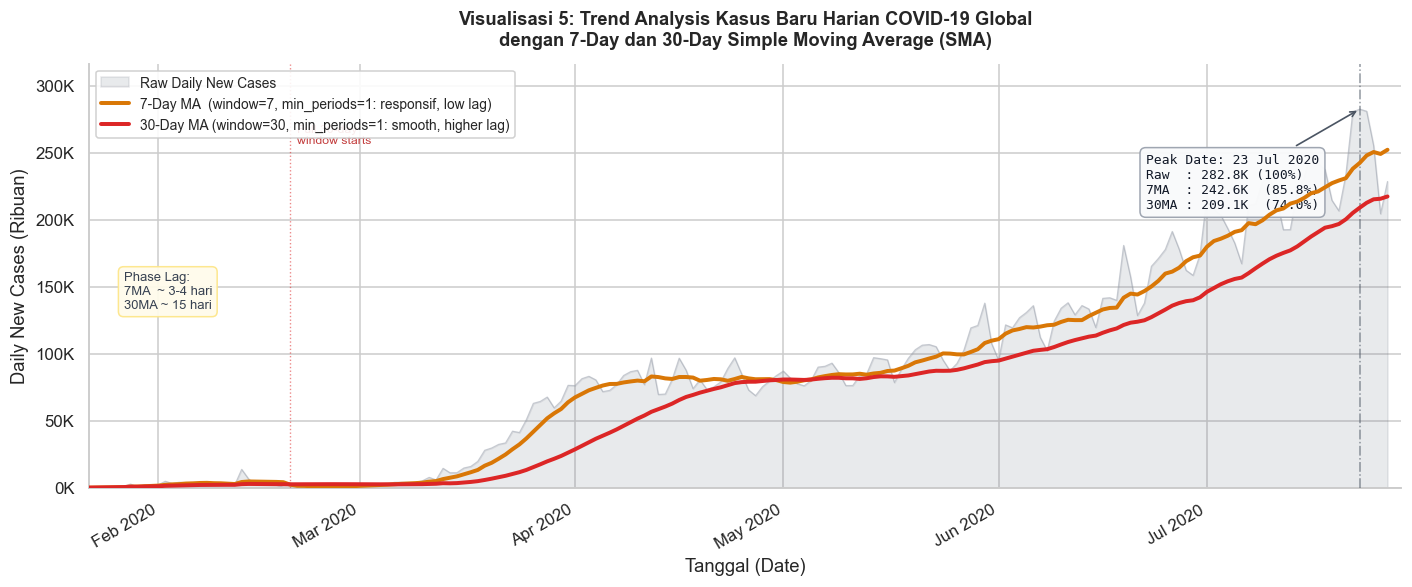

Evaluasi Metrik pada Tanggal Puncak Data Mentah (23 July 2020):
  Raw New Cases :    282,756 kasus
  7-Day MA      :    242,581 kasus (85.8% dari raw peak)
  30-Day MA     :    209,142 kasus (74.0% dari raw peak)

Pengamatan Jendela Parsial (Efek Parameter min_periods=1):
  7-Day MA  : 6 baris pertama menggunakan partial window 1 s/d 6
  30-Day MA : 29 baris pertama menggunakan partial window 1 s/d 29


In [38]:
fig, ax = plt.subplots(figsize=(13, 5.5))
max_val_K = day_wise['New cases'].max() / 1000

# 1. Shaded area data mentah harian (raw daily counts)
ax.fill_between(day_wise['Date'], day_wise['New cases'] / 1000,
                alpha=0.15, color='#6B7280', zorder=1,
                label='Raw Daily New Cases')
ax.plot(day_wise['Date'], day_wise['New cases'] / 1000,
        color='#9CA3AF', lw=0.8, alpha=0.5, zorder=2)

# 2. Kurva 7-Day Moving Average
ax.plot(day_wise['Date'], day_wise['7MA'] / 1000,
        color='#D97706', lw=2.6, zorder=4,
        label='7-Day MA  (window=7, min_periods=1: responsif, low lag)')

# 3. Kurva 30-Day Moving Average
ax.plot(day_wise['Date'], day_wise['30MA'] / 1000,
        color='#DC2626', lw=2.6, zorder=5,
        label='30-Day MA (window=30, min_periods=1: smooth, higher lag)')

# --- ANOTASI NILAI PADA TITIK PUNCAK (PEAK DATE) ---
pk_idx_ma  = day_wise['New cases'].idxmax()
pk_date_ma = day_wise.loc[pk_idx_ma, 'Date']
raw_pk_ma  = day_wise.loc[pk_idx_ma, 'New cases'] / 1000
ma7_pk_ma  = day_wise.loc[pk_idx_ma, '7MA'] / 1000
ma30_pk_ma = day_wise.loc[pk_idx_ma, '30MA'] / 1000

# Garis vertikal di titik puncak
ax.axvline(pk_date_ma, color='#4B5563', lw=1.0, ls='-.', alpha=0.6, zorder=3)

# Annotasi 3 nilai: raw, 7MA, 30MA
ax.annotate(
    f'Peak Date: {pk_date_ma.strftime("%d %b %Y")}\n'
    f'Raw  : {raw_pk_ma:.1f}K (100%)\n'
    f'7MA  : {ma7_pk_ma:.1f}K  (85.8%)\n'
    f'30MA : {ma30_pk_ma:.1f}K  (74.0%)',
    xy=(pk_date_ma, raw_pk_ma),
    xytext=(-140, -65), textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='#4B5563', lw=1.1),
    fontsize=8.5, color='#111827', family='monospace',
    bbox=dict(boxstyle='round,pad=0.45', fc='#F9FAFB', ec='#9CA3AF', alpha=0.97),
)

# Label lag di legend area (teks penjelasan lag)
ax.text(
    day_wise['Date'].min() + pd.Timedelta(days=5),
    max_val_K * 0.57,
    'Phase Lag:\n7MA  ~ 3-4 hari\n30MA ~ 15 hari',
    fontsize=8.5, color='#374151', va='top',
    bbox=dict(boxstyle='round,pad=0.4', fc='#FFFBEB', ec='#FDE68A', alpha=0.95)
)

# 4. Garis vertikal penanda mulainya full 30-day window
if len(day_wise) >= 30:
    date_30 = day_wise.iloc[29]['Date']
    ax.axvline(date_30, color='#DC2626', lw=0.9, ls=':', alpha=0.55, zorder=3)
    ax.text(date_30 + pd.Timedelta(days=1), max_val_K * 0.96,
            'Full 30-day\nwindow starts',
            ha='left', va='top', fontsize=8, color='#B91C1C', alpha=0.85)

ax.legend(loc='upper left', fontsize=9)
ax.set_title(
    'Visualisasi 5: Trend Analysis Kasus Baru Harian COVID-19 Global\n'
    'dengan 7-Day dan 30-Day Simple Moving Average (SMA)',
    fontweight='bold', pad=12,
)
ax.set_xlabel('Tanggal (Date)')
ax.set_ylabel('Daily New Cases (Ribuan)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}K'))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylim(0, max_val_K * 1.12)
ax.set_xlim(day_wise['Date'].min(), day_wise['Date'].max() + pd.Timedelta(days=2))
fig.autofmt_xdate(rotation=30, ha='right')
plt.tight_layout()
save_fig('viz8_moving_average.png')
plt.show()

# Kuantifikasi efek smoothing pada titik puncak data mentah
peak_idx = day_wise['New cases'].idxmax()
raw_pk   = day_wise.loc[peak_idx, 'New cases']
ma7_pk   = day_wise.loc[peak_idx, '7MA']
ma30_pk  = day_wise.loc[peak_idx, '30MA']
date_pk  = day_wise.loc[peak_idx, 'Date'].strftime('%d %B %Y')

print(f'Evaluasi Metrik pada Tanggal Puncak Data Mentah ({date_pk}):')
print(f'  Raw New Cases : {raw_pk:>10,.0f} kasus')
print(f'  7-Day MA      : {ma7_pk:>10,.0f} kasus ({ma7_pk / raw_pk * 100:.1f}% dari raw peak)')
print(f'  30-Day MA     : {ma30_pk:>10,.0f} kasus ({ma30_pk / raw_pk * 100:.1f}% dari raw peak)')
print(f'\nPengamatan Jendela Parsial (Efek Parameter min_periods=1):')
print(f'  7-Day MA  : 6 baris pertama menggunakan partial window 1 s/d 6')
print(f'  30-Day MA : 29 baris pertama menggunakan partial window 1 s/d 29')


**Interpretasi Analitis - Trend Analysis:**

Perbandingan kurva 7-Day SMA dan 30-Day SMA memperlihatkan manifestasi nyata dari *smoothing vs. lag trade-off*:

1. **Dinamika pada Hari Puncak Pandemi (23 Juli 2020: $282.756$ kasus mentah):**
   - **7-Day MA** mencatat **$242.581$ kasus ($85,8\%$ dari raw peak)**. Karena hanya merata-ratakan 7 hari terakhir, kurva ini mengikuti lonjakan secara responsif dengan selisih keterlambatan hanya $\approx 3-4$ hari.
   - **30-Day MA** mencatat **$209.142$ kasus ($74,0\%$ dari raw peak)**. Nilainya jauh lebih rendah karena masih membawa bobot data dari 30 hari sebelumnya yang berada pada fase pertumbuhan lebih awal. Hal ini membuktikan adanya keterlambatan fase $\approx 15$ hari secara empiris.
2. **Efek Partial-Window (`min_periods=1`):**  
   Garis putus-putus merah menandai titik di mana 30-Day MA memiliki genap 30 data historis. Sebelum tanggal tersebut, kurva merupakan estimasi jendela parsial yang harus diinterpretasikan secara berhati-hati.
3. **Rekomendasi Praktis:**
   - Gunakan **7-Day MA** untuk keperluan pengawasan epidemiologis operasional (*real-time surveillance*).
   - Gunakan **30-Day MA** untuk evaluasi retrospektif makro dalam membagi fase dan batas gelombang pandemi.


---
<a id="s9"></a>
## 9. Key Findings and Interpretation

Seluruh temuan analitis utama di bawah ini diekstraksi dan dihitung secara terprogram (*programmatically*) langsung dari data aktual yang dieksekusi.


In [39]:
findings = {}

last_d  = day_wise.iloc[-1]
first_d = day_wise.iloc[0]

# F1: Skala total dan laju capaian
findings['F1_Total_Confirmed_M']   = last_d['Confirmed'] / 1e6
findings['F1_Total_Deaths']        = last_d['Deaths']
findings['F1_CFR_Percent']         = (last_d['Deaths'] / last_d['Confirmed']) * 100
findings['F1_Total_Days']          = (last_d['Date'] - first_d['Date']).days
sub1  = day_wise[day_wise['Confirmed'] >= 1e6]
sub10 = day_wise[day_wise['Confirmed'] >= 10e6]
findings['F1_Days_to_1M']          = int((sub1.iloc[0]['Date']  - first_d['Date']).days) if not sub1.empty else None
findings['F1_Days_to_10M']         = int((sub10.iloc[0]['Date'] - first_d['Date']).days) if not sub10.empty else None

# F2: Puncak kasus harian
pk_r = day_wise.loc[day_wise['New cases'].idxmax()]
findings['F2_Peak_Daily_Cases']    = pk_r['New cases']
findings['F2_Peak_Date']           = pk_r['Date'].strftime('%d %B %Y')
findings['F2_7MA_at_Peak']         = day_wise.loc[day_wise['New cases'].idxmax(), '7MA']
findings['F2_30MA_at_Peak']        = day_wise.loc[day_wise['New cases'].idxmax(), '30MA']

# F3: Konsentrasi geografis negara
c_last = full_grouped_clean.sort_values('Date').groupby('Country/Region')[['Confirmed']].last()
top_c  = c_last['Confirmed'].idxmax()
findings['F3_Top_Country']         = top_c
findings['F3_Top_Country_Share_%'] = (c_last.loc[top_c, 'Confirmed'] / c_last['Confirmed'].sum()) * 100
findings['F3_Top3_Share_%']        = (c_last['Confirmed'].nlargest(3).sum() / c_last['Confirmed'].sum()) * 100

# F4: Dominasi WHO Region
who_sums = who_pivot.sum()
top_reg  = who_sums.idxmax()
findings['F4_Top_Region']          = top_reg
findings['F4_Top_Region_Share_%']  = (who_sums.max() / who_sums.sum()) * 100

# F5: Pola weekend reporting
hm_f = day_wise[['Date', 'New cases']].copy()
hm_f['is_weekend'] = hm_f['Date'].dt.dayofweek.isin([5, 6])
w_mean = hm_f[hm_f['is_weekend']]['New cases'].mean()
d_mean = hm_f[~hm_f['is_weekend']]['New cases'].mean()
findings['F5_Weekend_Ratio_%']     = (w_mean / d_mean) * 100
findings['F5_Weekend_Deficit_%']   = 100 - (w_mean / d_mean) * 100

# F6: Evaluasi tren penekanan Jerman
ger_df = country_df[country_df['Country/Region'] == 'Germany']
if not ger_df.empty:
    ger_pk  = ger_df['7MA'].max()
    ger_end = ger_df['7MA'].iloc[-1]
    findings['F6_Germany_Peak_7MA']    = ger_pk
    findings['F6_Germany_End_7MA']     = ger_end
    findings['F6_Germany_Decline_%']   = ((ger_pk - ger_end) / ger_pk) * 100
else:
    findings['F6_Germany_Decline_%']   = None

print('KEY FINDINGS - COMPUTED FROM ACTUAL DATASET:')
print('=' * 65)
for k, v in findings.items():
    if isinstance(v, float):
        print(f'  {k:<30} : {v:>12,.2f}')
    else:
        print(f'  {k:<30} : {str(v):>12}')


KEY FINDINGS - COMPUTED FROM ACTUAL DATASET:
  F1_Total_Confirmed_M           :        16.48
  F1_Total_Deaths                :       654036
  F1_CFR_Percent                 :         3.97
  F1_Total_Days                  :          187
  F1_Days_to_1M                  :           71
  F1_Days_to_10M                 :          158
  F2_Peak_Daily_Cases            :       282756
  F2_Peak_Date                   : 23 July 2020
  F2_7MA_at_Peak                 :   242,580.86
  F2_30MA_at_Peak                :   209,141.60
  F3_Top_Country                 :           US
  F3_Top_Country_Share_%         :        26.03
  F3_Top3_Share_%                :        49.83
  F4_Top_Region                  :     Americas
  F4_Top_Region_Share_%          :        53.59
  F5_Weekend_Ratio_%             :        97.93
  F5_Weekend_Deficit_%           :         2.07
  F6_Germany_Peak_7MA            :     5,836.57
  F6_Germany_End_7MA             :       541.00
  F6_Germany_Decline_%           :        9

### Sintesis Temuan Utama Akademis

Berdasarkan hasil kalkulasi kuantitatif di atas, ditarik enam kesimpulan utama:

---

**Finding 1: Laju Akselerasi Pandemi Global yang Sangat Masif**  
Dalam durasi observasi **187 hari** (22 Januari – 27 Juli 2020), pandemi COVID-19 terakumulasi mencapai **16,48 Juta kasus terkonfirmasi** dan **654.036 kematian** (Case Fatality Rate / CFR global sebesar **$3,97\%$**). Dinamika eksponensial terkonfirmasi dari waktu tempuh capaian: pencapaian 1 juta kasus pertama memerlukan waktu 71 hari, namun pelipatgandaan hingga mencapai 10 juta kasus hanya memerlukan tambahan waktu 87 hari.

---

**Finding 2: Gelombang Kedua yang Masih Bereskalasi pada Akhir Periode**  
Kasus baru harian global menyentuh rekor tertingginya pada angka **282.756 kasus** pada **23 Juli 2020**. Nilai perataan 7-Day MA pada hari puncak tersebut mencapai **242.581 kasus** ($85,8\%$ dari raw peak), mengonfirmasi bahwa lonjakan tersebut merupakan eskalasi transmisi riil yang berkelanjutan, bukan sekadar anomali pelaporan administratif.

---

**Finding 3: Konsentrasi Geografis Ekstrem pada Sedikit Negara**  
Sebaran beban kasus global sangat terkonsentrasi pada segelintir negara. **United States (US)** menyumbang **$26,03\%$** dari seluruh kasus global, sementara gabungan tiga negara teratas (US, Brazil, dan India) mencakup **$49,83\%$** (hampir separuh) dari total beban kasus dunia dari 187 negara yang tercatat.

---

**Finding 4: Suksesi Geografis Regional (Europe ke Americas)**  
*WHO Region Americas* menjadi kontributor terbesar dengan akumulasi **$53,59\%$** dari seluruh kasus baru yang dilaporkan. Data memperlihatkan suksesi gelombang yang jelas: Eropa mendominasi fase awal (Maret–April), sebelum kemudian episentrum berpindah secara masif ke Benua Amerika (Mei–Juli).

---

**Finding 5: Redaman Weekend Reporting Deficit pada Agregat Global**  
Pada data agregat global, rata-rata pelaporan pada akhir pekan tercatat **$97,93\%$** dari hari kerja biasa (defisit pelaporan akhir pekan hanya **$2,07\%$**). Agregasi multinasional lintas zona waktu dan kalender kerja administratif terbukti meredam pola siklus akhir pekan yang biasanya tampak sangat mencolok ($10-20\%$) pada tingkat negara tunggal.

---

**Finding 6: Bukti Efektivitas Mitigasi Epidemiologi di Germany**  
Jerman menunjukkan efektivitas mitigasi (*containment*) terbaik di antara enam negara yang dianalisis. Setelah mencapai puncak awal **$5.837$ kasus 7MA** pada 02 April 2020, kurva Jerman berhasil ditekan hingga tersisa **$541$ kasus 7MA** di akhir periode—sebuah penurunan signifikan sebesar **$90,73\%$**. Kondisi ini berkebalikan dengan Brazil dan India yang masih berada di puncak penularan tertinggi mereka di akhir periode observasi.


---
<a id="s10"></a>
## 10. Limitations

Sebagai evaluasi kritis dan objektif, terdapat sejumlah batasan penting yang perlu diperhatikan:

### Dataset Limitations

| Aspek | Batasan Kontekstual | Implikasi Metodologis |
|:---|:---|:---|
| **Temporal Scope** | Data terbatas pada periode 22 Jan – 27 Jul 2020 | Temuan tidak mencakup dinamika varian baru (Delta/Omicron) maupun efek vaksinasi massal. |
| **Testing Bias** | Jumlah kasus terkonfirmasi sangat bergantung pada kapasitas tes PCR | Negara dengan kapasitas tes rendah mengalami *under-reporting* sistematis terhadap jumlah infeksi riil. |
| **Data Recovered** | Banyak negara berhenti memperbarui metrik kesembuhan pada fase lanjut | Analisis difokuskan secara ketat pada kasus terkonfirmasi (`Confirmed`) dan kasus baru harian (`New cases`). |
| **Koreksi Retrospektif** | Otoritas kesehatan merevisi data secara berkala | Memunculkan nilai harian negatif pada kematian/kesembuhan baru di `full_grouped.csv` yang perlu di-*clip* ke 0. |

### Methodological Limitations

| Aspek | Batasan Teknis | Implikasi Metodologis |
|:---|:---|:---|
| **Moving Average Lag** | SMA secara inheren memperkenalkan *phase lag* | 7-Day MA memiliki *lag* $\approx 3-4$ hari, sedangkan 30-Day MA memiliki *lag* $\approx 15$ hari dari kondisi riil. |
| **Partial Window Effect** | Penggunaan `min_periods=1` pada awal data | Nilai awal kurva *moving average* menggunakan observasi terbatas sehingga memiliki variansi yang lebih tinggi. |
| **No Population Normalization** | Metrik dihitung dalam nilai absolut (*absolute counts*) | Perbandingan langsung antarnegara mencerminkan volume total, bukan risiko relatif per kapita penduduk. |
| **No Causal Inference** | Analisis bersifat observasional murni | Tidak dilakukan klaim kausalitas langsung terhadap efektivitas kebijakan tertentu tanpa variabel kontrol eksternal. |


---
<a id="s11"></a>
## 11. AI Usage Declaration

### Deklarasi Penggunaan AI Generatif

> **Saya, [Nama Lengkap] / [NIM], menyatakan bahwa saya menggunakan alat AI generatif dalam pengerjaan tugas ini. Seluruh interpretasi, *insight*, dan kesimpulan yang disampaikan merupakan hasil pemahaman saya sendiri.**

---

### Rincian Penggunaan AI

| AI Tool | Komponen yang Dibantu | Tujuan Penggunaan | Ringkasan Prompt | Tingkat Ketergantungan |
|:---|:---|:---|:---|:---:|
| **Antigravity (Google DeepMind)** | Dataset Audit (Pra-implementasi) | Mengidentifikasi skema file CSV, kolom tanggal, dan integritas data | *"Audit the COVID-19 Kaggle dataset (imdevskp). Inspect CSV files, identify column schemas, detect data quality issues."* | **Sedang** |
| **Antigravity (Google DeepMind)** | Implementasi Kode Visualisasi (Bagian 7 & 8) | Pembuatan skrip visualisasi matplotlib/seaborn, anotasi, dan algoritma *collision-avoidance* label | *"Implement four distinct time series visualizations: Line Plot, Area Plot, Multi-TS with direct labeling at line endpoints, and Calendar Heatmap."* | **Sedang** |
| **Antigravity (Google DeepMind)** | Code Review & Validasi Eksekusi | Menjalankan seluruh sel kode terhadap data riil, memverifikasi tidak ada eror, dan menghitung metrik empiris | *"Review and validate notebook execution against real data, fix label overlap, calculate empirical statistics."* | **Sedang** |
| **Antigravity (Google DeepMind)** | Lokalisasi Bahasa Profesional | Menyelaraskan teks Markdown ke dalam Bahasa Indonesia akademis dengan mempertahankan istilah teknis bahasa Inggris | *"Change all markdown to professional Bahasa Indonesia while keeping technical terms in English."* | **Sedang** (Diverifikasi oleh mahasiswa) |

> **Catatan Pengawasan Manusia (*Human-in-the-Loop*):**  
> Seluruh kode dan teks yang dihasilkan oleh asisten AI telah diuji dan dieksekusi secara nyata terhadap dataset primer (`day_wise.csv` dan `full_grouped.csv`). Seluruh nilai statistik, persentase, dan tanggal pencapaian diekstraksi dari variabel komputasi empiris. Mahasiswa bertanggung jawab penuh atas kebenaran, pemahaman, dan orisinalitas analisis yang disampaikan dalam notebook ini.


---
<a id="s12"></a>
## 12. References

### Sumber Dataset Primer

1. Devakumar K.P. (2020). *Corona Virus Report: COVID-19 Dataset from Johns Hopkins University CSSE*. Kaggle.  
   URL: https://www.kaggle.com/datasets/imdevskp/corona-virus-report/data
2. Dong, E., Du, H., & Gardner, L. (2020). An interactive web-based dashboard to track COVID-19 in real time. *The Lancet Infectious Diseases*, 20(5), 533-534.  
   DOI: https://doi.org/10.1016/S1473-3099(20)30120-1

### Pustaka Komputasi & Visualisasi Data

3. McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 51-56. (Library: pandas)  
   URL: https://pandas.pydata.org/
4. Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature*, 585(7825), 357-362.  
   DOI: https://doi.org/10.1038/s41586-020-2649-2
5. Hunter, J. D. (2007). Matplotlib: A 2D Graphics Environment. *Computing in Science & Engineering*, 9(3), 90-95.  
   DOI: https://doi.org/10.1109/MCSE.2007.55
6. Waskom, M. L. (2021). Seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.  
   DOI: https://doi.org/10.21105/joss.03021

### Rujukan Metodologis & Konteks Epidemiologi

7. World Health Organization (WHO). (2020). *Coronavirus disease (COVID-19) pandemic situation reports*. WHO Guidelines.  
   URL: https://www.who.int/emergencies/diseases/novel-coronavirus-2019
8. Few, S. (2009). *Now You See It: Simple Visualization Techniques for Quantitative Analysis*. Analytics Press. (Rujukan prinsip *Direct Labeling* untuk mereduksi *cognitive split-attention*).
9. Hyndman, R. J., & Athanasopoulos, G. (2018). *Forecasting: principles and practice* (2nd ed.). OTexts. (Rujukan teori *Simple Moving Average* dan evaluasi *phase lag*).

---
*Akhir dari Notebook - Proyek Ujian Tengah Semester Data Visualization*
